# Homework 6: Non-negative FIR Filter Design
## Name: Jon Knapp
### Date: November 10, 2026
### Class: EE 522 Discrete Time Processing

## AI Disclosure:

AI was used in the following ways:
* Code generation
* Markdown generation
* Checking my work and my logic
* Process suggestions
* Project analysis to fit non-negative FIR filters

## Problem 1: Select three different non-causal, non-negative impulse responses with even symmetry. The purpose of these filters is to smooth the signals they are applied to, where the amount of smoothing is controlled by the duration of the impulse response. Please scale the impulse responses for a DC gain of 1. Give a mathematical or verbal description of each impulse response, and provide your rationale for using this impulse response.

### How I'm interpreting the requirements:
Each filter is non-causal and centered at $n = 0$, defined on $-M \le n \le M$ with length $N = 2M + 1$.
All three satisfy:

- **Non-negative:** $h[n] \ge 0$ for all $n$
- **Even symmetry:** $h[n] = h[-n]$
- **Unit DC gain:** $H(e^{j0}) = \sum_{n=-M}^{M} h[n] = 1$

The half-length $M$ sets the duration of the impulse response, and therefore the amount of smoothing.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.special import comb
from matplotlib.ticker import MaxNLocator

plt.style.use("default")   # white-background figures regardless of editor theme


def rectangular(M):
    # Moving average (boxcar): 2M+1 equal taps, each 1/(2M+1).
    n = np.arange(-M, M + 1)
    h = np.ones_like(n, dtype=float) / (2 * M + 1)
    return n, h


def triangular(M):
    # Bartlett: linear taper from the center, zero just outside |n| = M.
    n = np.arange(-M, M + 1)
    h = (M + 1 - np.abs(n)) / (M + 1) ** 2
    return n, h


def binomial(M):
    # Binomial: row 2M of Pascal's triangle, scaled by 2^(-2M).
    n = np.arange(-M, M + 1)
    h = comb(2 * M, M + n, exact=False) / 2.0 ** (2 * M)
    return n, h


def check_filter(name, n, h):
    # Confirm the three required properties numerically.
    print(f"{name:12s}  N = {len(h):3d}   sum(h) = {h.sum():.12f}   "
          f"min(h) = {h.min():.3e}   symmetric = {np.allclose(h, h[::-1])}")


def plot_impulse(n, h, title, ax=None):
    if ax is None:
        _, ax = plt.subplots(figsize=(8, 3.5))
    ax.stem(n, h, basefmt="k-")
    ax.set_xlabel("Sample index $n$")
    ax.set_ylabel("$h[n]$")
    ax.set_title(title)
    ax.grid(True, alpha=0.3)
    ax.set_ylim(bottom=0)
    ax.xaxis.set_major_locator(MaxNLocator(integer=True))
    return ax


M = 10   # half-length used for the example plots below (N = 21)

### Filter 1: Rectangular (moving average / boxcar)

$$
h_{\text{rect}}[n] =
\begin{cases}
\dfrac{1}{2M+1}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

Every sample in the window receives equal weight, so the output is the arithmetic mean of the $2M+1$ input samples centered on $n$.

**DC gain:** $\displaystyle\sum_{n=-M}^{M} \frac{1}{2M+1} = \displaystyle\sum_{n=-M}^{-1} \frac{1}{2M+1} + \frac{1}{2M+1} + \displaystyle\sum_{n=1}^{M} \frac{1}{2M+1} = \frac{M}{2M+1} + \frac{1}{2M+1} + \frac{M}{2M+1} = \frac{2M+1}{2M+1} = 1$

**Frequency response.** Start from the DTFT definition. Only the $2M+1$ nonzero taps contribute:
$$
H_{\text{rect}}(e^{j\omega}) = \sum_{n=-\infty}^{\infty} h_{\text{rect}}[n]\,e^{-j\omega n} = \frac{1}{2M+1}\sum_{n=-M}^{M} e^{-j\omega n}
$$

*Step 1: Shift the index so the sum starts at 0.* Let $k = n + M$, so $n = k - M$ and $k$ runs from $0$ to $2M$:
$$
H_{\text{rect}}(e^{j\omega}) = \frac{1}{2M+1}\sum_{k=0}^{2M} e^{-j\omega (k-M)} = \frac{e^{j\omega M}}{2M+1}\sum_{k=0}^{2M} \left(e^{-j\omega}\right)^{k}
$$

*Step 2: Sum the finite geometric series.* With ratio $r = e^{-j\omega}$ and $2M+1$ terms, $\sum_{k=0}^{2M} r^k = \dfrac{1-r^{2M+1}}{1-r}$ for $r \ne 1$ (that is, $\omega \ne 0$):
$$
H_{\text{rect}}(e^{j\omega}) = \frac{e^{j\omega M}}{2M+1}\cdot\frac{1 - e^{-j\omega(2M+1)}}{1 - e^{-j\omega}}
$$

*Step 3: Factor out half-angle exponentials.* Pull out the exponential at half of each exponent, so that what remains is a difference of conjugates. Then use $e^{j\theta} - e^{-j\theta} = 2j\sin\theta$:
$$
\begin{aligned}
1 - e^{-j\omega(2M+1)} &= e^{-j\omega(2M+1)/2}\left(e^{j\omega(2M+1)/2} - e^{-j\omega(2M+1)/2}\right) = e^{-j\omega(2M+1)/2}\;2j\sin\!\big(\omega(2M+1)/2\big) \\[4pt]
1 - e^{-j\omega} &= e^{-j\omega/2}\left(e^{j\omega/2} - e^{-j\omega/2}\right) = e^{-j\omega/2}\;2j\sin(\omega/2)
\end{aligned}
$$

*Step 4: Substitute and simplify.* The $2j$ factors cancel, and the remaining exponentials combine to 1:
$$
H_{\text{rect}}(e^{j\omega}) = \frac{1}{2M+1}\cdot\underbrace{e^{j\omega M}\,e^{-j\omega(2M+1)/2}\,e^{j\omega/2}}_{e^{j\omega(M - M - 1/2 + 1/2)}\;=\;1}\cdot\frac{\sin\!\big(\omega(2M+1)/2\big)}{\sin(\omega/2)}
$$
so
$$
H_{\text{rect}}(e^{j\omega}) = \frac{1}{2M+1}\,\frac{\sin\!\big(\omega(2M+1)/2\big)}{\sin(\omega/2)}
$$

This is the Dirichlet kernel. The complex exponentials cancel because the filter is centered at $n = 0$; this is the even symmetry $h[n] = h[-n]$ at work. As a result, $H_{\text{rect}}(e^{j\omega})$ is purely real.

*Check at DC:* As $\omega \to 0$, $\sin\!\big(\omega(2M+1)/2\big) \approx \omega(2M+1)/2$ and $\sin(\omega/2) \approx \omega/2$, so $H_{\text{rect}}(e^{j\omega}) \to 1$. This matches the DC gain above.

*Phase:* $H_{\text{rect}}(e^{j\omega})$ is real but not always positive. It is positive in the main lobe, $|\omega| < 2\pi/(2M+1)$, and changes sign at each zero, $\omega = 2\pi k/(2M+1)$. The phase is therefore $0$ where $H_{\text{rect}} > 0$ and $\pi$ where $H_{\text{rect}} < 0$.

**Rationale:** The simplest possible smoother and the baseline for comparison.

Rectangular   N =  21   sum(h) = 1.000000000000   min(h) = 4.762e-02   symmetric = True


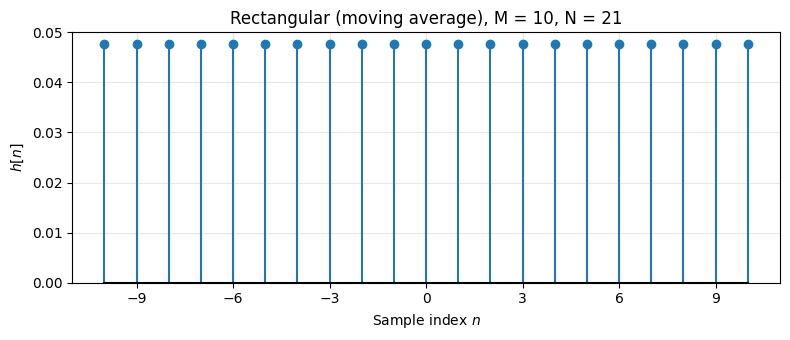

In [2]:
n, h_rect = rectangular(M)
check_filter("Rectangular", n, h_rect)
plot_impulse(n, h_rect, f"Rectangular (moving average), M = {M}, N = {2*M+1}")
plt.tight_layout()
plt.show()

### Filter 2: Triangular (Bartlett)

$$
h_{\text{tri}}[n] =
\begin{cases}
\dfrac{M+1-|n|}{(M+1)^2}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

The weights fall off linearly from a peak of $\frac{1}{M+1}$ at $n = 0$ and reach zero at $|n| = M+1$, so all $2M+1$ taps in the window are strictly positive.

**DC gain:**
$$
\sum_{n=-M}^{M} (M+1-|n|) = (M+1) + 2\sum_{k=1}^{M}(M+1-k) = (M+1) + M(M+1) = (M+1)^2
$$
so dividing by $(M+1)^2$ gives a sum of 1.

**Frequency response:** The triangle equals the convolution of two length-$(M+1)$ rectangles, $h_{\text{tri}} = h_{\text{rect},M+1} * h_{\text{rect},M+1}$, so its response is the square of a Dirichlet kernel:

$$
H_{\text{tri}}(e^{j\omega}) = \left[\frac{1}{M+1}\,\frac{\sin\!\big(\omega(M+1)/2\big)}{\sin(\omega/2)}\right]^2 \ge 0
$$

**Rationale:** Tapering the edges trades a wider main lobe for much lower sidelobes (about $-26$ dB), and because $H_{\text{tri}}(e^{j\omega})$ is never negative, the filter never inverts the sign of any frequency component.

Triangular    N =  21   sum(h) = 1.000000000000   min(h) = 8.264e-03   symmetric = True


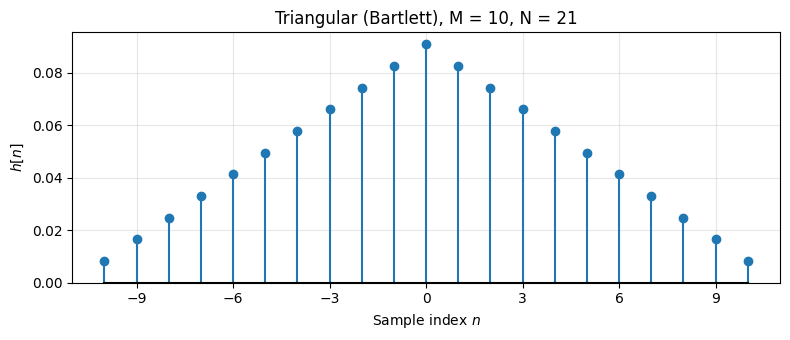

In [3]:
n, h_tri = triangular(M)
check_filter("Triangular", n, h_tri)
plot_impulse(n, h_tri, f"Triangular (Bartlett), M = {M}, N = {2*M+1}")
plt.tight_layout()
plt.show()

### Filter 3: Binomial

$$
h_{\text{bin}}[n] =
\begin{cases}
\dfrac{1}{2^{2M}}\dbinom{2M}{M+n}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

The taps are row $2M$ of Pascal's triangle. Equivalently, $h_{\text{bin}}$ is the two-tap average $\left[\tfrac12, \tfrac12\right]$ convolved with itself $2M$ times (then centered at $n = 0$).

<div style="background-color:#ffe6e6; border:3px solid #cc0000; border-radius:6px; padding:14px; text-align:center;">
  <span style="color:#cc0000; font-size:1.5em; font-weight:bold;">
    ⚠️ THE FOLLOWING DERIVATION WAS DONE WITH AI ⚠️
  </span>
</div>

**DC gain.** The DC gain is the frequency response at $\omega = 0$, which is the sum of the taps:
$$
H_{\text{bin}}(e^{j0}) = \sum_{n=-M}^{M} h_{\text{bin}}[n] = \frac{1}{2^{2M}}\sum_{n=-M}^{M}\binom{2M}{M+n}
$$

*Step 1: Shift the index so the sum starts at 0.* Let $k = M + n$, so $k$ runs from $0$ to $2M$:
$$
H_{\text{bin}}(e^{j0}) = \frac{1}{2^{2M}}\sum_{k=0}^{2M}\binom{2M}{k}
$$

*Step 2: Apply the binomial theorem.* For any $a$ and $b$, $(a+b)^{N} = \sum_{k=0}^{N}\binom{N}{k}a^{k}b^{N-k}$. With $a = b = 1$ and $N = 2M$:
$$
\sum_{k=0}^{2M}\binom{2M}{k} = (1+1)^{2M} = 2^{2M}
$$

*Step 3: Divide by the scale factor.*
$$
H_{\text{bin}}(e^{j0}) = \frac{2^{2M}}{2^{2M}} = 1
$$
The factor $1/2^{2M}$ is chosen exactly to cancel the sum of row $2M$ of Pascal's triangle.

**Frequency response.** Start from the DTFT definition. Only the $2M+1$ nonzero taps contribute:
$$
H_{\text{bin}}(e^{j\omega}) = \sum_{n=-\infty}^{\infty} h_{\text{bin}}[n]\,e^{-j\omega n} = \frac{1}{2^{2M}}\sum_{n=-M}^{M}\binom{2M}{M+n}e^{-j\omega n}
$$

*Step 1: Shift the index so the sum starts at 0.* Let $k = n + M$, so $n = k - M$ and $k$ runs from $0$ to $2M$:
$$
H_{\text{bin}}(e^{j\omega}) = \frac{1}{2^{2M}}\sum_{k=0}^{2M}\binom{2M}{k}e^{-j\omega(k-M)} = \frac{e^{j\omega M}}{2^{2M}}\sum_{k=0}^{2M}\binom{2M}{k}\left(e^{-j\omega}\right)^{k}
$$

*Step 2: Apply the binomial theorem.* With $a = e^{-j\omega}$, $b = 1$, and $N = 2M$, the sum collapses to a single power:
$$
\sum_{k=0}^{2M}\binom{2M}{k}\left(e^{-j\omega}\right)^{k} = \left(1 + e^{-j\omega}\right)^{2M}
\quad\Longrightarrow\quad
H_{\text{bin}}(e^{j\omega}) = e^{j\omega M}\left(\frac{1 + e^{-j\omega}}{2}\right)^{2M}
$$
The term in parentheses is the DTFT of the two-tap average $\left[\tfrac12, \tfrac12\right]$. Raising it to the power $2M$ is the convolution theorem at work: convolving that average with itself $2M$ times multiplies its response by itself $2M$ times.

*Step 3: Factor out the half-angle exponential.* Pull out $e^{-j\omega/2}$, so that what remains is a sum of conjugates. Then use $e^{j\theta} + e^{-j\theta} = 2\cos\theta$:
$$
1 + e^{-j\omega} = e^{-j\omega/2}\left(e^{j\omega/2} + e^{-j\omega/2}\right) = e^{-j\omega/2}\;2\cos(\omega/2)
\quad\Longrightarrow\quad
\frac{1 + e^{-j\omega}}{2} = e^{-j\omega/2}\cos(\omega/2)
$$
The factor $e^{-j\omega/2}$ is the half-sample delay of one two-tap stage.

*Step 4: Substitute and simplify.* Raising to the power $2M$ turns the half-sample delays into $e^{-j\omega M}$, which cancels the $e^{j\omega M}$ from Step 1:
$$
H_{\text{bin}}(e^{j\omega}) = \underbrace{e^{j\omega M}\,e^{-j\omega M}}_{=\,1}\cos^{2M}\!\left(\frac{\omega}{2}\right)
$$
so
$$
H_{\text{bin}}(e^{j\omega}) = \cos^{2M}\!\left(\frac{\omega}{2}\right)
$$

As with the rectangular filter, the complex exponentials cancel because the filter is centered at $n = 0$, so $H_{\text{bin}}(e^{j\omega})$ is purely real.

*Check at DC:* $\cos^{2M}(0) = 1$, which matches the DC gain above.

*Properties:*
- **Non-negative:** the exponent $2M$ is even, so $H_{\text{bin}}(e^{j\omega}) \ge 0$ for every $\omega$. The phase is therefore $0$ at all frequencies (it is undefined only at $\omega = \pi$, where $H_{\text{bin}} = 0$).
- **Monotonic:** on $0 \le \omega \le \pi$, $\cos(\omega/2)$ falls steadily from $1$ to $0$ and is never negative, so $\cos^{2M}(\omega/2)$ also falls steadily from $1$ at $\omega = 0$ to $0$ at $\omega = \pi$. There are no sidelobes and no ripple.

**Rationale:** Binomial filters are used a lot in image processing because it's the cost-effective solution for wanting to use a Gaussian filter. It's being tested here to allow me to further investigate it.

Binomial      N =  21   sum(h) = 1.000000000000   min(h) = 9.537e-07   symmetric = True


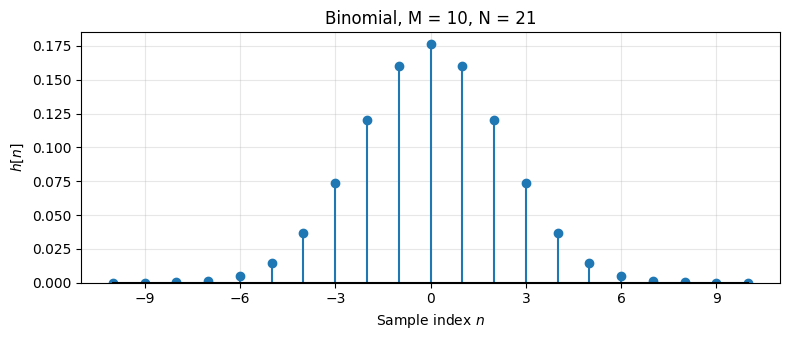

In [4]:
n, h_bin = binomial(M)
check_filter("Binomial", n, h_bin)
plot_impulse(n, h_bin, f"Binomial, M = {M}, N = {2*M+1}")
plt.tight_layout()
plt.show()

### Side-by-side comparison

All three filters with the same half-length $M$. Note the different vertical scales: the taps in each filter always sum to 1, so a more concentrated filter has a taller peak.

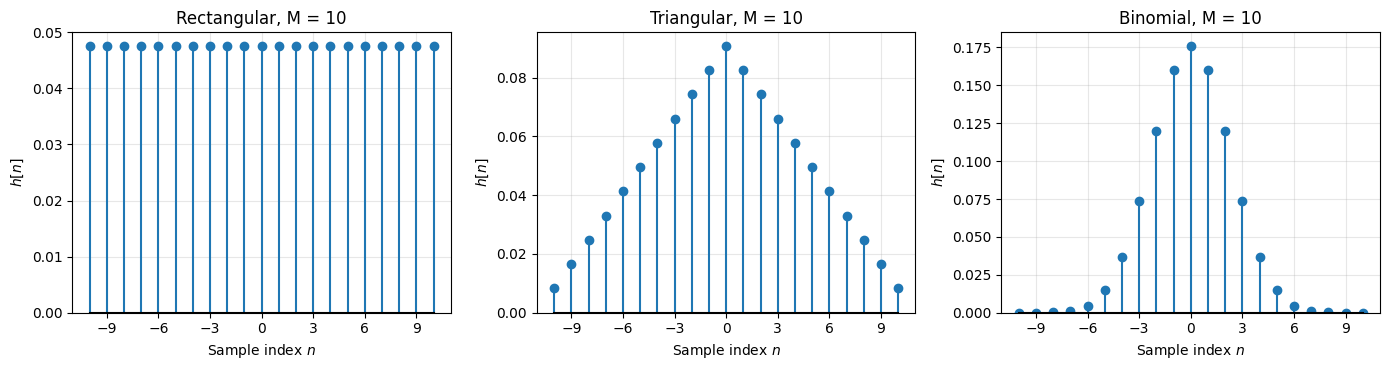

In [5]:
fig, axes = plt.subplots(1, 3, figsize=(14, 3.8))
for ax, (name, fn) in zip(axes, [("Rectangular", rectangular),
                                 ("Triangular", triangular),
                                 ("Binomial", binomial)]):
    n, h = fn(M)
    plot_impulse(n, h, f"{name}, M = {M}", ax=ax)
plt.tight_layout()
plt.show()

## Problem 2: For each of the three filters, provide the following:
* An explanation of how you enforce the requirement that the DC gain is 1
* A plot that shows how the cutoff frequency of the filter is related to the duration of the filter
* For each of the cutoff frequencies of 0.05 pi, 0.1 pi, and 0.2 pi, include the following in your report:
  * Magnitude response
  * Phase response
  * Group delay
  * Impulse response
  * Time domain example of the input and output signals applied to the following signals. Please include the input and output signals on the same plot with clear labels that make it clear which signal is the input and which is the output.
    * A white noise, signal with 200 samples, a mean of 1, and a variance of 1. Be mindful of edge conditions.
    * A shifted step x[n] = u[n-100] with 200 samples. Be mindful of edge conditions.
    * 100 samples of a sinusoid with a frequency of 0.1 pi radians per sample.
  * Power spectral density plot of the input signal
    * _**Please use the periodogram method or an appropriately scaled FFT to compute the PSD on all signals.**_
  * Power spectral density plot of the output signal
    * _**Please use the periodogram method or an appropriately scaled FFT to compute the PSD on all signals.**_


### _An explanation of how you enforce the requirement that the DC gain is 1_

### Filter 1: Rectangular (moving average / boxcar)

$$
h_{\text{rect}}[n] =
\begin{cases}
\dfrac{1}{2M+1}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

**DC gain:** $\displaystyle\sum_{n=-M}^{M} \frac{1}{2M+1} = \frac{2M+1}{2M+1} = 1$

### Filter 2: Triangular (Bartlett)

$$
h_{\text{tri}}[n] =
\begin{cases}
\dfrac{M+1-|n|}{(M+1)^2}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

**DC gain:**
$$
\sum_{n=-M}^{M} (M+1-|n|) = (M+1) + 2\sum_{k=1}^{M}(M+1-k) = (M+1) + M(M+1) = (M+1)^2
$$
so dividing by $(M+1)^2$ gives a sum of 1.

### Filter 3: Binomial

$$
h_{\text{bin}}[n] =
\begin{cases}
\dfrac{1}{2^{2M}}\dbinom{2M}{M+n}, & |n| \le M \\[6pt]
0, & \text{otherwise}
\end{cases}
$$

**DC gain:** By the binomial theorem,
$$
\sum_{k=0}^{2M}\binom{2M}{k} = (1+1)^{2M} = 2^{2M}
$$
so dividing by $2^{2M}$ gives a sum of exactly 1.

### _A plot that shows how the cutoff frequency of the filter is related to the duration of the filter_

**Cutoff definition.** I use the $-3$ dB (half-power) frequency: the smallest $\omega_c > 0$ where
$$
|H(e^{j\omega_c})| = \frac{1}{\sqrt{2}}.
$$
Because each $h[n]$ is even-symmetric about $n = 0$, the frequency response is purely real:
$$
H(e^{j\omega}) = h[0] + 2\sum_{n=1}^{M} h[n]\cos(\omega n),
$$
so I evaluate it on a dense grid over $[0, \pi]$, find the first grid point that drops below $1/\sqrt{2}$, and refine the crossing with a root finder.

**Duration** is the number of taps, $N = 2M + 1$. Since $M$ must be an integer, only a discrete set of cutoffs is achievable, so for each target cutoff I pick the $M$ whose cutoff is closest.

In [6]:
from scipy.optimize import brentq


def amplitude_response(h, M, w):
    # Real (zero-phase) response of an even-symmetric filter centered at n = 0.
    k = np.arange(1, M + 1)
    return h[M] + 2 * np.cos(np.outer(w, k)) @ h[M + 1:]


def cutoff_3dB(filter_fn, M, n_grid=8192):
    # First frequency (rad/sample) where |H| falls to 1/sqrt(2).
    _, h = filter_fn(M)
    level = 1 / np.sqrt(2)
    w = np.linspace(0, np.pi, n_grid)
    A = amplitude_response(h, M, w)
    i = np.argmax(np.abs(A) < level)          # first grid point below the level
    f = lambda x: amplitude_response(h, M, np.array([x]))[0] - level
    return brentq(f, w[i - 1], w[i])


filters = {"Rectangular": rectangular,
           "Triangular": triangular,
           "Binomial": binomial}

M_range = np.arange(1, 121)
N_range = 2 * M_range + 1
cutoffs = {name: np.array([cutoff_3dB(fn, M) for M in M_range])
           for name, fn in filters.items()}

targets = np.array([0.05, 0.1, 0.2]) * np.pi

### Cutoff vs. duration for each filter

Each plot shows the $-3$ dB cutoff (in units of $\pi$) against the filter length $N$. The dashed lines mark the three target cutoffs, and the marked points are the lengths that come closest to each target.

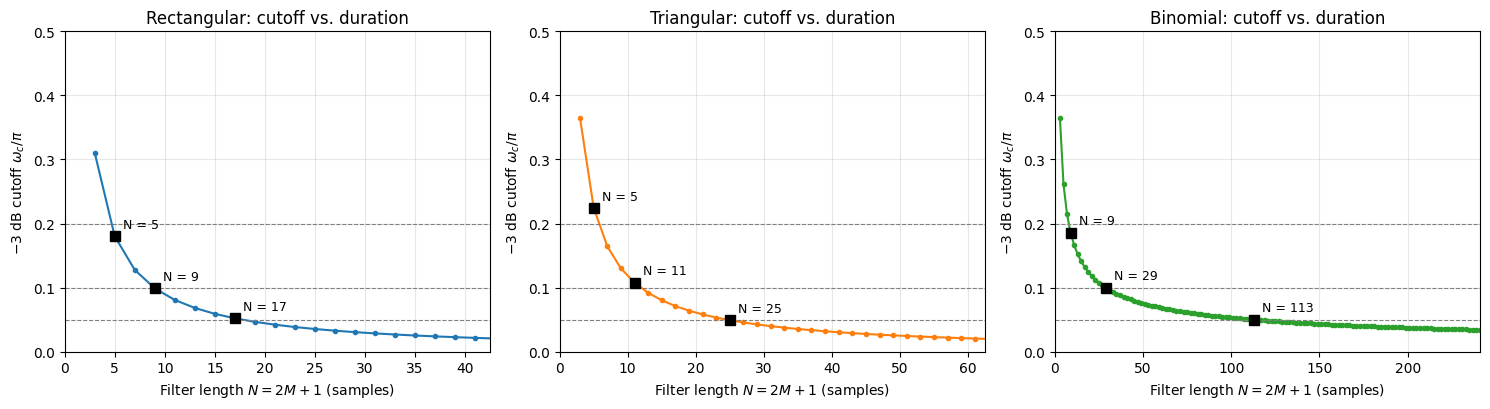

In [7]:
colors = {"Rectangular": "C0", "Triangular": "C1", "Binomial": "C2"}
design = {}   # chosen M for each (filter, target), used in the rest of Problem 2

fig, axes = plt.subplots(1, 3, figsize=(15, 4.2))
for ax, name in zip(axes, filters):
    wc = cutoffs[name]
    ax.plot(N_range, wc / np.pi, "o-", ms=3, color=colors[name], label="$\\omega_c$")
    design[name] = {}
    for wt in targets:
        i = np.argmin(np.abs(wc - wt))
        design[name][wt / np.pi] = M_range[i]
        ax.axhline(wt / np.pi, color="gray", ls="--", lw=0.8)
        ax.plot(N_range[i], wc[i] / np.pi, "ks", ms=7)
        ax.annotate(f"N = {N_range[i]}", (N_range[i], wc[i] / np.pi),
                    textcoords="offset points", xytext=(6, 6), fontsize=9)
    ax.set_title(f"{name}: cutoff vs. duration")
    ax.set_xlabel("Filter length $N = 2M + 1$ (samples)")
    ax.set_ylabel("$-3$ dB cutoff $\\omega_c / \\pi$")
    ax.set_ylim(0, 0.5)
    N_max = 2 * max(design[name].values()) + 1
    ax.set_xlim(0, min(2.5 * N_max, N_range[-1]))   # zoom to the region of interest
    ax.grid(True, alpha=0.3)
plt.tight_layout()
plt.show()

### All three filters on log-log axes

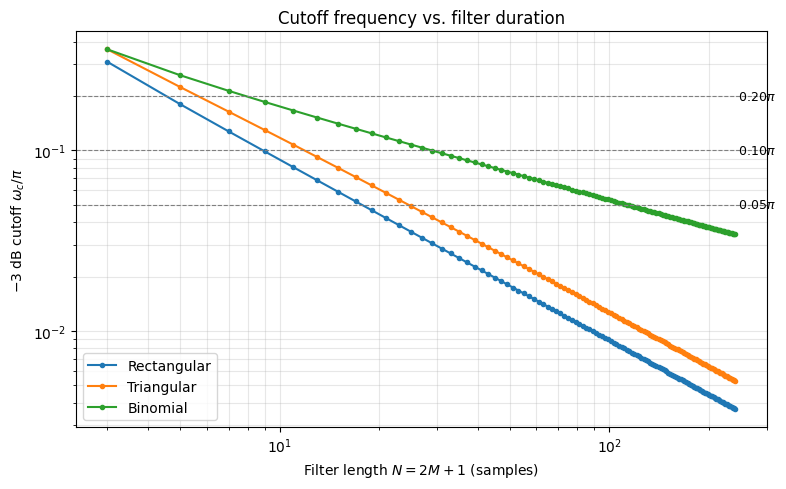

In [8]:
fig, ax = plt.subplots(figsize=(8, 5))
for name in filters:
    wc = cutoffs[name]
    ax.loglog(N_range, wc / np.pi, "o-", ms=3, color=colors[name], label=name)
    # Fitted slope over the longer filters, where the asymptotic behavior holds
    sel = M_range >= 10
    slope = np.polyfit(np.log(N_range[sel]), np.log(wc[sel]), 1)[0]
for wt in targets:
    ax.axhline(wt / np.pi, color="gray", ls="--", lw=0.8)
    ax.text(N_range[-1], wt / np.pi, f" {wt/np.pi:.2f}$\\pi$", va="center", fontsize=9)
ax.set_xlabel("Filter length $N = 2M + 1$ (samples)")
ax.set_ylabel("$-3$ dB cutoff $\\omega_c / \\pi$")
ax.set_title("Cutoff frequency vs. filter duration")
ax.grid(True, which="both", alpha=0.3)
ax.legend()
plt.tight_layout()
plt.show()

### Filter lengths chosen for each target cutoff

In [9]:
print(f"{'Filter':12s} {'Target':>8s} {'M':>5s} {'N':>5s} {'Actual wc/pi':>14s} {'Error':>8s}")
for name, fn in filters.items():
    for target, M_sel in design[name].items():
        wc = cutoff_3dB(fn, M_sel) / np.pi
        print(f"{name:12s} {target:7.2f}π {M_sel:5d} {2*M_sel+1:5d} "
              f"{wc:13.4f}π {100*(wc-target)/target:+7.1f}%")

Filter         Target     M     N   Actual wc/pi    Error
Rectangular     0.05π     8    17        0.0522π    +4.4%
Rectangular     0.10π     4     9        0.0990π    -1.0%
Rectangular     0.20π     2     5        0.1803π    -9.8%
Triangular      0.05π    12    25        0.0492π    -1.6%
Triangular      0.10π     5    11        0.1077π    +7.7%
Triangular      0.20π     2     5        0.2245π   +12.3%
Binomial        0.05π    56   113        0.0501π    +0.1%
Binomial        0.10π    14    29        0.1000π    -0.0%
Binomial        0.20π     4     9        0.1860π    -7.0%


For each filter and target cutoff, I use the length $N = 2M + 1$ chosen above and show three figures:

1. **Filter characteristics:** impulse response, magnitude, phase, and group delay.
2. **Time-domain examples:** input and output for white noise, the shifted step, and the sinusoid.
3. **Power spectral densities (PSDs):** input and output for each test signal.

### Phase and group delay

Each filter is even-symmetric about $n = 0$, so $H(e^{j\omega}) = A(\omega)$ is real. A real number has a phase of $0$ when it is positive and $\pm\pi$ when it is negative:
$$
\angle H(e^{j\omega}) =
\begin{cases}
0, & A(\omega) > 0 \\
\pm\pi, & A(\omega) < 0
\end{cases}
$$

- **Triangular and binomial:** $A(\omega) \ge 0$, so the phase is always $0$.
- **Rectangular:** the negative sidelobes cause jumps of $\pi$.
- **Group delay:** zero at every frequency, so the output is not shifted in time.
- **Causal version:** implementing the filter as $h[n - M]$ adds a linear phase of $-M\omega$ and a constant delay of $M$ samples (the dashed curves).

Phase and group delay are left blank where $|H| < -200$ dB, because there the response is just roundoff noise. This only affects the long binomial filters.

### Edge handling

**What is an edge region?** To compute the output $y[n]$, the filter needs the inputs $x[n-M]$ through $x[n+M]$: $M$ samples on each side of $n$. The signal only has samples $0 \le n \le L-1$, so near the ends some of the needed samples do not exist. An output sample has a complete window only when
$$
n - M \ge 0 \quad \text{and} \quad n + M \le L - 1 \qquad \Longleftrightarrow \qquad M \le n \le L - 1 - M .
$$
Every other output sample is in the **edge region**, which is shaded gray on the plots.

*Example (binomial, $M = 56$, $N = 113$):*
- **White noise and step ($L = 200$):** windows are complete only for $56 \le n \le 143$. The first 56 and last 56 samples are shaded.
- **Sinusoid ($L = 100$):** a complete window would need $56 \le n \le 43$, which is impossible. The filter (113 samples) is longer than the signal (100 samples), so *every* output sample has a truncated window, and the whole plot is shaded.

**What to do about the missing samples.** Zero padding assumes the missing samples are 0. That pulls the output toward 0 near the edges, which is badly wrong for the mean-1 noise and the step. Instead I use **normalized convolution**: I use only the samples that exist, then divide by the sum of the taps that were used:
$$
y[n] = \frac{\sum_{k} h[k]\,x[n-k]}{\sum_{k} h[k]}, \qquad \text{both sums over } k \text{ with } 0 \le n-k \le L-1 .
$$
*Example at $n = 0$:* the window covers $-56 \le n \le 56$, but only $x[0], \dots, x[56]$ exist. The taps used are the center tap and one side, which sum to about $0.54$. Dividing by $0.54$ rescales those taps to sum to 1. The output is then a true weighted average of $x[0], \dots, x[56]$, rather than an average in which 46% of the weight lands on zeros.

Because $h[n] \ge 0$, the denominator is always positive. A constant input therefore gives exactly the same constant output everywhere, including at the edges, so the DC gain stays 1. In the interior, the denominator is 1 and this is ordinary convolution.

<div style="background-color:#ffe6e6; border:3px solid #cc0000; border-radius:6px; padding:14px; text-align:center;">
  <span style="color:#cc0000; font-size:1.5em; font-weight:bold;">
    ⚠️ THE FOLLOWING DERIVATION WAS DONE WITH AI ⚠️
  </span>
</div>

### PSD estimation

Every PSD is a **periodogram**: one FFT over the entire record, with no segmenting and no averaging. Welch's method fails for the step, because most of its segments would be all 0s or all 1s.
$$
\hat{P}(\omega_k) = \frac{c_k\,|X[k]|^2}{2\pi L}, \qquad c_k = 2 \text{ except } c_k = 1 \text{ at } \omega = 0 \text{ and } \pi
$$

- Dividing by $2\pi L$ makes the area under the PSD equal the signal's average power (Parseval's relation). The check below confirms this.
- Zero padding to 1024 points only smooths the plotted curve; it does not add resolution.
- The mean is kept, so the DC component is visible.
- For white noise, the dashed lines show the theory: $\sigma^2/\pi$ for the input and $|H|^2\sigma^2/\pi$ for the output.

**What to look for**

- **White noise:** a single periodogram is noisy (swings of about $\pm 10$ dB are normal). The output follows the theory on average.
- **Leakage floor:** with no window, the periodogram effectively uses a rectangular window. The noise's DC component leaks across the band and creates a floor near $-30$ dB. That floor comes from the estimator, not the filter.
- **Step:** the periodogram sees the record as a 0 → 1 → 0 pulse, like one period of a square wave, which gives closely spaced nulls in the input PSD. The filter smooths the jump at $n = 100$, leaving only the drop at the end of the record. The output PSD is therefore a smooth curve about 6 dB lower.
- **Sinusoid:** the input PSD peaks at $0.1\pi$ (5 full cycles in 100 samples). The output peak is scaled by $|H(e^{j0.1\pi})|^2$: it is heavily attenuated when the cutoff is below $0.1\pi$ and nearly unchanged when the cutoff is $0.2\pi$.


In [10]:
import warnings
from scipy.signal import periodogram, group_delay

# ---- Test signals (one fixed noise realization, reused for every design) ----
rng = np.random.default_rng(42)
L_long = 200
z = rng.standard_normal(L_long)
x_noise = 1.0 + (z - z.mean()) / z.std(ddof=1)            # exactly mean 1, variance 1
x_step = (np.arange(L_long) >= 100).astype(float)          # u[n - 100]
x_sine = np.cos(0.1 * np.pi * np.arange(100))              # 0.1*pi rad/sample

test_signals = [("White noise (mean 1, var 1)", x_noise),
                ("Shifted step $u[n-100]$", x_step),
                ("Sinusoid, $\\omega_0 = 0.1\\pi$", x_sine)]

# ---- PSD settings: periodogram over the entire record (no segmenting or averaging) ----
NFFT_PSD = 1024                                    # zero-pad only to sample the DTFT finely
PSD_KW = dict(fs=2 * np.pi, window="boxcar", nfft=NFFT_PSD, detrend=False,
              return_onesided=True, scaling="density")

w_grid = np.linspace(0, np.pi, 4096)


def apply_filter(x, h):
    # Non-causal filtering with normalized convolution at the edges.
    M = (len(h) - 1) // 2
    L = len(x)
    num = np.convolve(x, h)[M:M + L]               # centered (zero-phase) output
    den = np.convolve(np.ones(L), h)[M:M + L]      # sum of taps that overlap the data
    return num / den


def psd_db(x):
    # Periodogram of the whole signal: P(w) = |X(e^jw)|^2 / (2*pi*L), doubled for 0 < w < pi
    f, P = periodogram(x, **PSD_KW)                # f in rad/sample, 0 to pi
    return f, 10 * np.log10(np.maximum(P, 1e-12))


def shade_edges(ax, L, M):
    edge = min(M, L / 2)
    ax.axvspan(-0.5, edge - 0.5, color="gray", alpha=0.15, lw=0)
    ax.axvspan(L - edge - 0.5, L - 0.5, color="gray", alpha=0.15, lw=0,
               label="Edge region (window truncated)")


def report_design(name, target):
    fn = filters[name]
    key = min(design[name], key=lambda t: abs(t - target))   # float-safe lookup
    M = design[name][key]
    n, h = fn(M)
    wc = cutoff_3dB(fn, M)
    tag = f"{name}, target $\\omega_c = {target:g}\\pi$ (M = {M}, N = {2*M+1}, actual $\\omega_c = {wc/np.pi:.4f}\\pi$)"

    # ---------- Figure 1: filter characteristics ----------
    A = amplitude_response(h, M, w_grid)
    mag_db = 20 * np.log10(np.maximum(np.abs(A), 1e-6))
    tiny = np.abs(A) < 1e-10                       # below -200 dB: numerically zero
    phase = np.where(A < 0, np.pi, 0.0)            # angle of a real-valued response
    phase[tiny] = np.nan

    h_causal = h                                   # same taps, indexed 0..2M
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        _, gd_causal = group_delay((h_causal, [1.0]), w=w_grid)
    gd_causal[tiny] = np.nan                       # unreliable where |H| is ~0
    gd_noncausal = gd_causal - M

    fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
    fig.suptitle(f"Filter characteristics: {tag}", fontsize=12)

    a = ax[0, 0]
    a.stem(n, h, basefmt="k-")
    a.set_title("Impulse response $h[n]$")
    a.set_xlabel("Sample index $n$")
    a.set_ylabel("$h[n]$")
    a.set_ylim(bottom=0)
    a.xaxis.set_major_locator(MaxNLocator(integer=True))

    a = ax[0, 1]
    a.plot(w_grid / np.pi, mag_db, color="C0")
    a.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
    a.axvline(target, color="C3", ls=":", lw=1.2, label=f"Target {target:g}$\\pi$")
    a.axvline(wc / np.pi, color="k", ls="--", lw=0.8, label=f"Actual {wc/np.pi:.3f}$\\pi$")
    a.set_title("Magnitude response $|H(e^{j\\omega})|$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Magnitude (dB)")
    a.set_ylim(-80, 5)
    a.legend(fontsize=8, loc="upper right")

    a = ax[1, 0]
    a.plot(w_grid / np.pi, phase / np.pi, color="C0", label="Non-causal (as applied)")
    a.set_title("Phase response $\\angle H(e^{j\\omega})$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Phase ($\\times\\pi$ rad)")
    a.set_ylim(-1.2, 1.2)
    a.legend(fontsize=8, loc="lower right")

    a = ax[1, 1]
    a.plot(w_grid / np.pi, gd_noncausal, color="C0", label="Non-causal (as applied)")
    a.plot(w_grid / np.pi, gd_causal, color="C1", ls="--",
           label=f"Causal version $h[n-M]$ (delay M = {M})")
    a.set_title("Group delay $\\tau_g(\\omega)$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Group delay (samples)")
    a.set_ylim(-0.1 * M - 1, 1.2 * M + 1)
    a.legend(fontsize=8, loc="center right")

    for a in ax.flat:
        a.grid(True, alpha=0.3)
    for a in [ax[0, 1], ax[1, 0], ax[1, 1]]:
        a.set_xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # ---------- Figure 2: time-domain examples ----------
    fig, ax = plt.subplots(3, 1, figsize=(13, 10))
    fig.suptitle(f"Time-domain examples: {tag}", fontsize=12)
    for a, (label, x) in zip(ax, test_signals):
        y = apply_filter(x, h)
        k = np.arange(len(x))
        shade_edges(a, len(x), M)
        a.plot(k, x, color="0.55", lw=1.0, marker=".", ms=3, label="Input $x[n]$")
        a.plot(k, y, color="C3", lw=2.0, label="Output $y[n]$ (filtered)")
        a.set_title(label)
        a.set_xlabel("Sample index $n$")
        a.set_ylabel("Amplitude")
        a.set_xlim(-1, len(x))
        a.grid(True, alpha=0.3)
    handles, labels = ax[0].get_legend_handles_labels()
    fig.legend(handles, labels, loc="upper center", ncol=3, fontsize=9,
               bbox_to_anchor=(0.5, 0.965), frameon=False)
    plt.tight_layout(rect=[0, 0, 1, 0.94])
    plt.show()

    # ---------- Figure 3: PSDs of input and output ----------
    H2 = np.abs(amplitude_response(h, M, w_grid)) ** 2
    fig, ax = plt.subplots(1, 3, figsize=(15, 4.5))
    fig.suptitle(f"Power spectral densities: {tag}", fontsize=12)
    for a, (label, x) in zip(ax, test_signals):
        y = apply_filter(x, h)
        f_in, P_in = psd_db(x)
        f_out, P_out = psd_db(y)
        a.plot(f_in / np.pi, P_in, color="0.45", label="Input PSD")
        a.plot(f_out / np.pi, P_out, color="C3", label="Output PSD")
        if x is x_noise:
            a.plot(w_grid / np.pi, 10 * np.log10(np.full_like(w_grid, 1 / np.pi)),
                   color="0.45", ls="--", lw=0.8, label="Input theory $\\sigma^2/\\pi$")
            a.plot(w_grid / np.pi, 10 * np.log10(np.maximum(H2 / np.pi, 1e-12)),
                   color="C3", ls="--", lw=0.8, label="Output theory $|H|^2\\sigma^2/\\pi$")
        a.axvline(target, color="C0", ls=":", lw=1.0, label=f"Cutoff {target:g}$\\pi$")
        a.set_title(label)
        a.set_xlabel("Frequency $\\omega/\\pi$")
        a.set_ylabel("PSD (dB per rad/sample)")
        a.set_xlim(0, 1)
        a.set_ylim(-80, 30)
        a.grid(True, alpha=0.3)
        a.legend(fontsize=7, loc="upper right")
    plt.tight_layout()
    plt.show()

#### PSD scaling check

This check confirms that `scipy.signal.periodogram` matches the hand-scaled FFT $c_k|X[k]|^2/(2\pi L)$, and that the area under each PSD equals the signal's average power.


In [11]:
signal_names = ["White noise", "Shifted step", "Sinusoid"]
print(f"{'Signal':14s} {'L':>4s} {'max |periodogram - FFT|':>24s} {'Area under PSD':>15s} {'mean(x^2)':>10s}")
for name, (_, x) in zip(signal_names, test_signals):
    L = len(x)
    f, P = periodogram(x, **PSD_KW)
    X = np.fft.rfft(x, NFFT_PSD)                   # one-sided FFT, 0 to pi
    c_k = np.full(len(X), 2.0)
    c_k[0] = 1.0                                   # DC is not doubled
    c_k[-1] = 1.0                                  # neither is pi (NFFT_PSD is even)
    P_fft = c_k * np.abs(X) ** 2 / (2 * np.pi * L)
    area = np.sum(P) * (2 * np.pi / NFFT_PSD)      # rectangle-rule integral over 0 to pi
    print(f"{name:14s} {L:4d} {np.max(np.abs(P - P_fft)):24.2e} {area:15.6f} {np.mean(x**2):10.6f}")


Signal            L  max |periodogram - FFT|  Area under PSD  mean(x^2)
White noise     200                 3.55e-14        1.995000   1.995000
Shifted step    200                 7.11e-15        0.500000   0.500000
Sinusoid        100                 3.55e-15        0.500000   0.500000


### Rectangular (moving average)

#### Rectangular, $\omega_c = 0.05\pi$

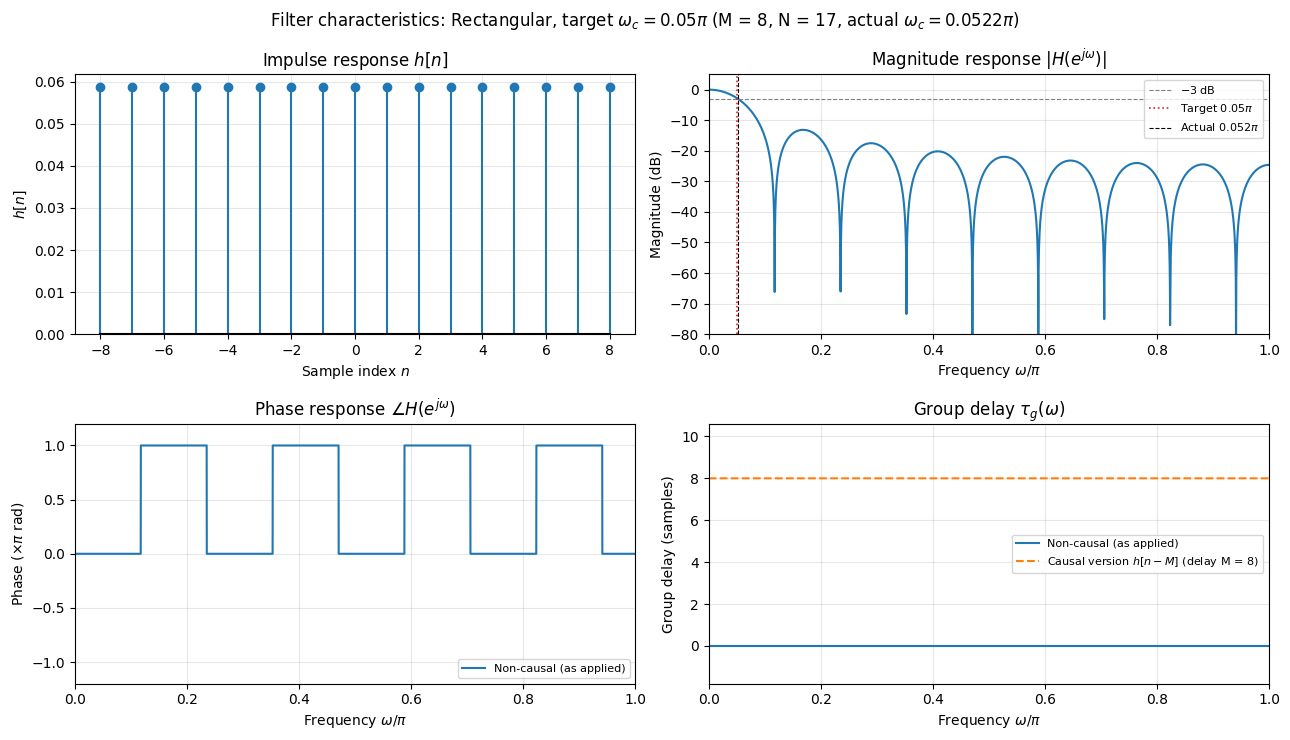

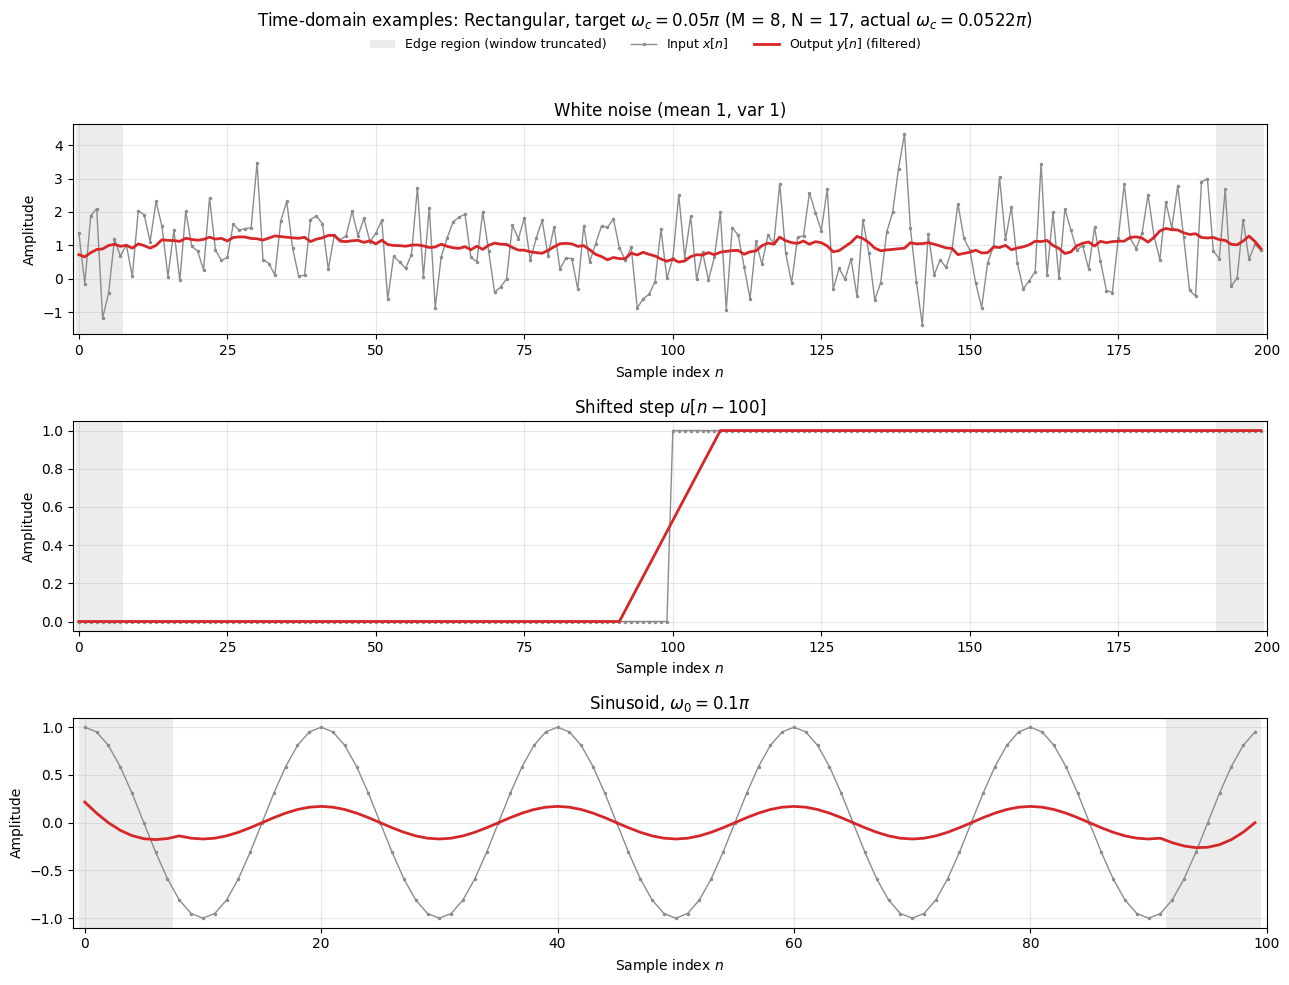

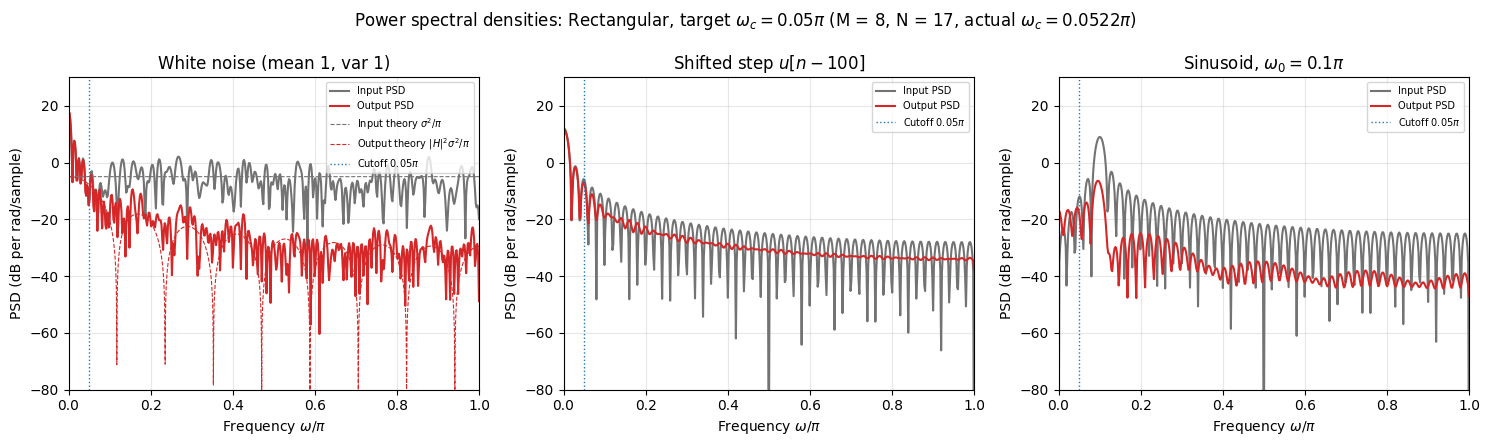

In [12]:
report_design("Rectangular", 0.05)

#### Rectangular, $\omega_c = 0.1\pi$

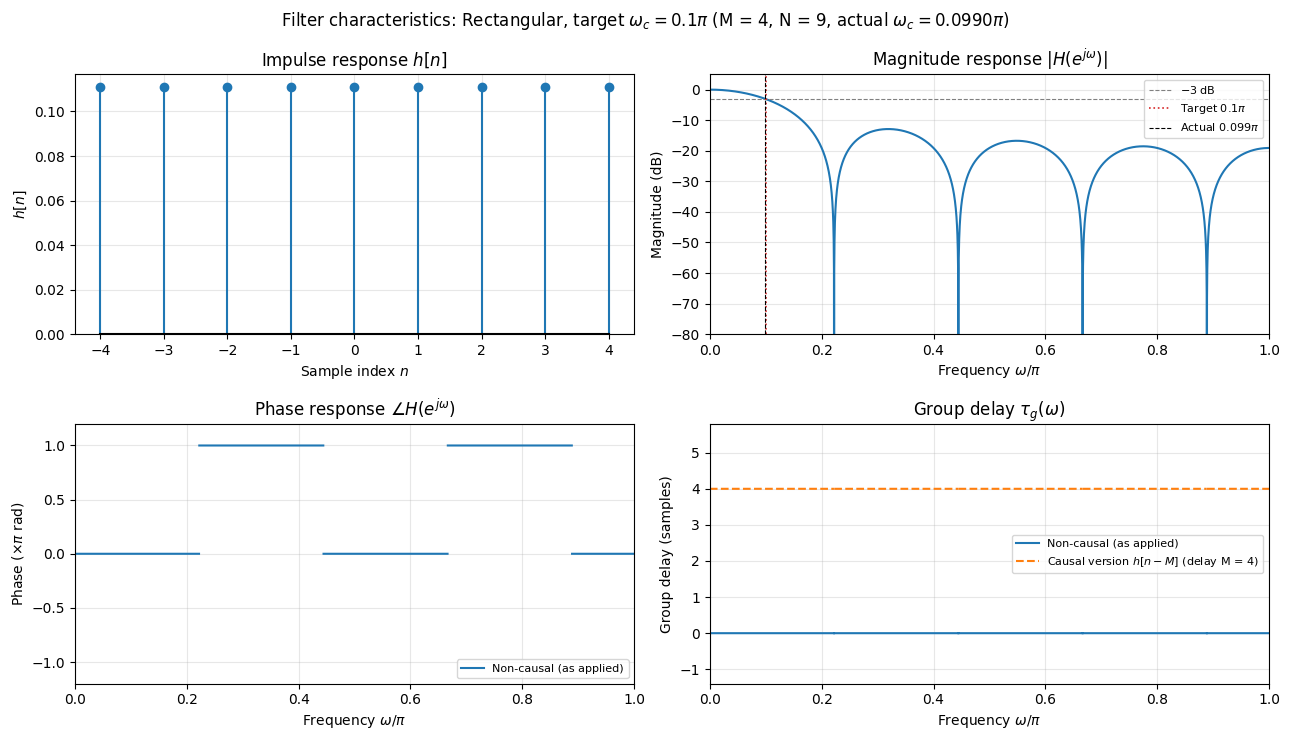

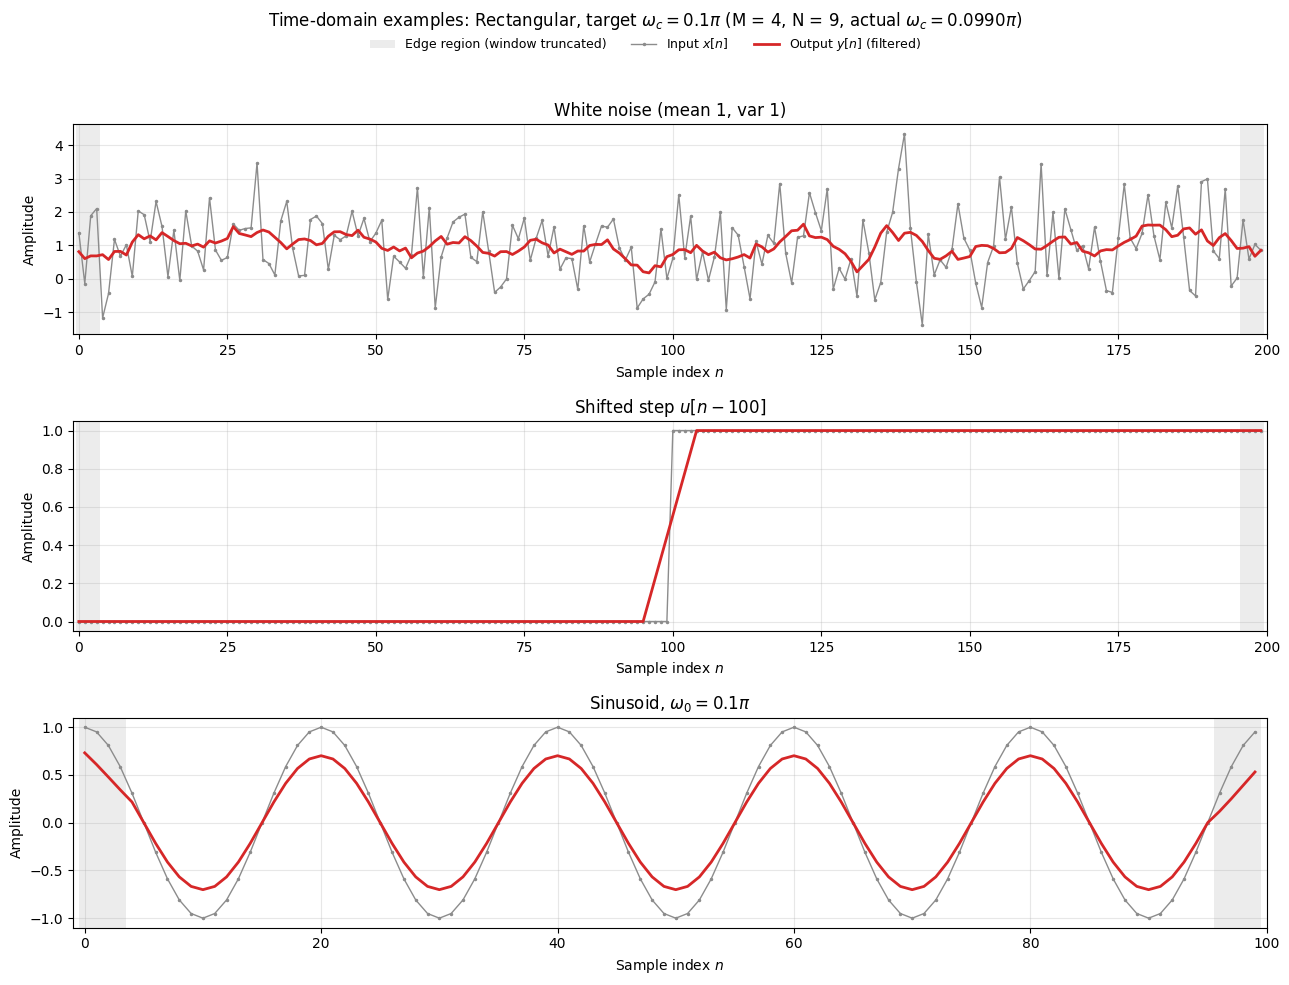

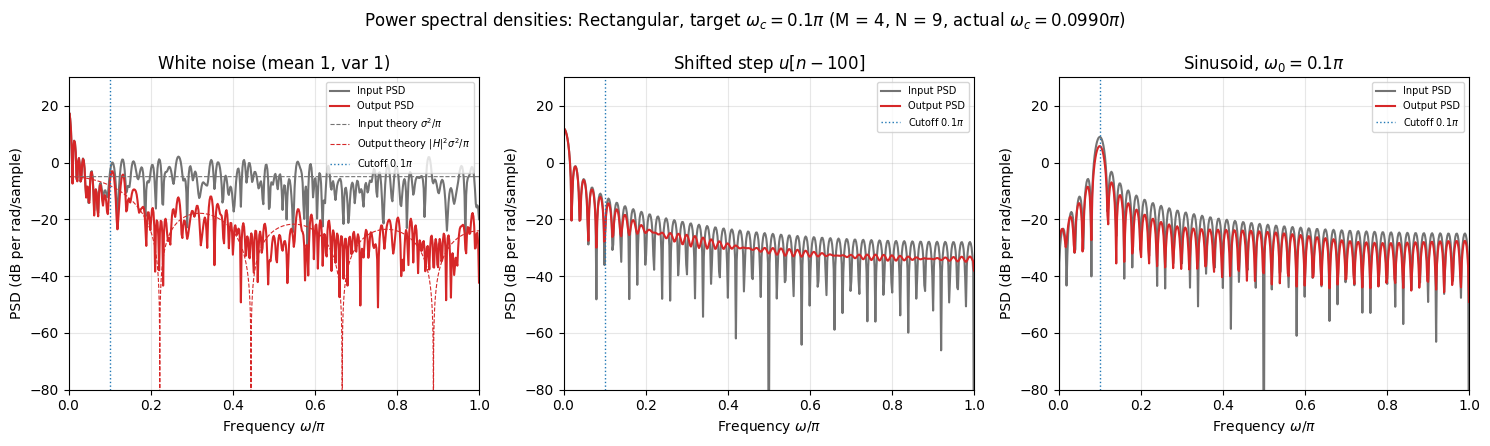

In [13]:
report_design("Rectangular", 0.1)

#### Rectangular, $\omega_c = 0.2\pi$

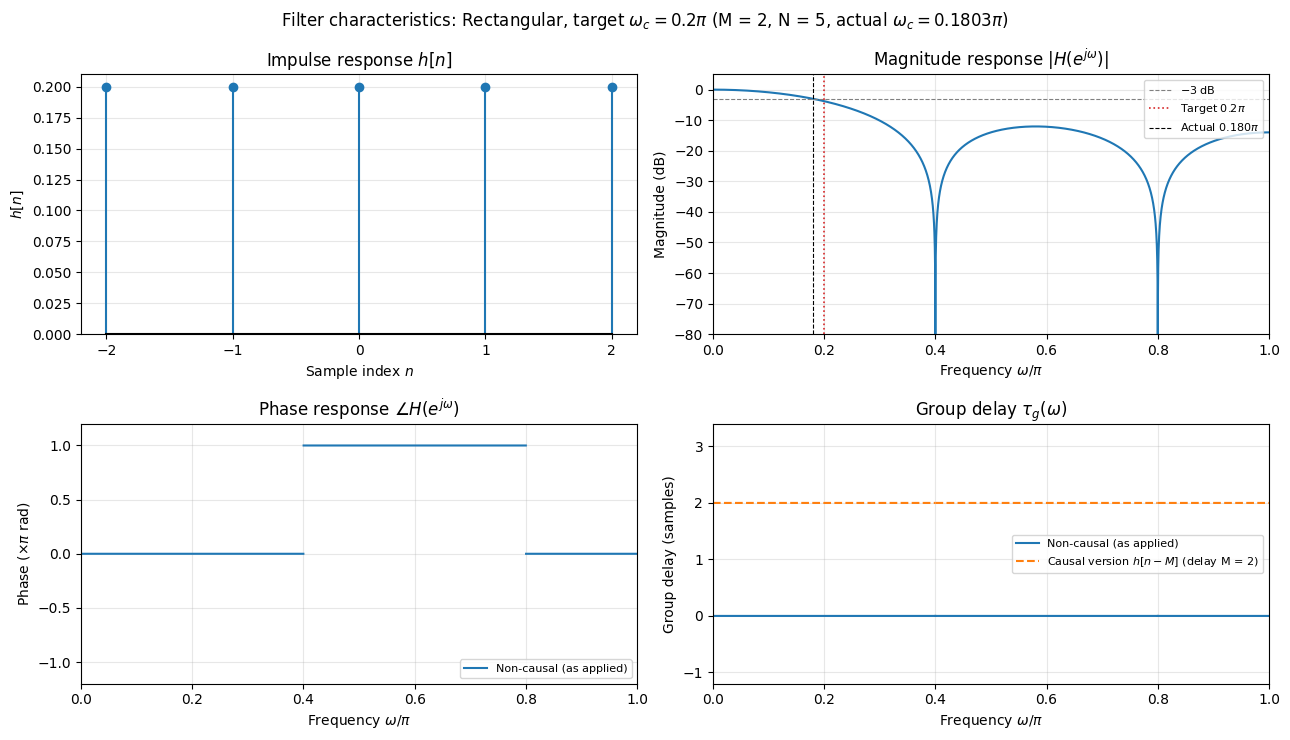

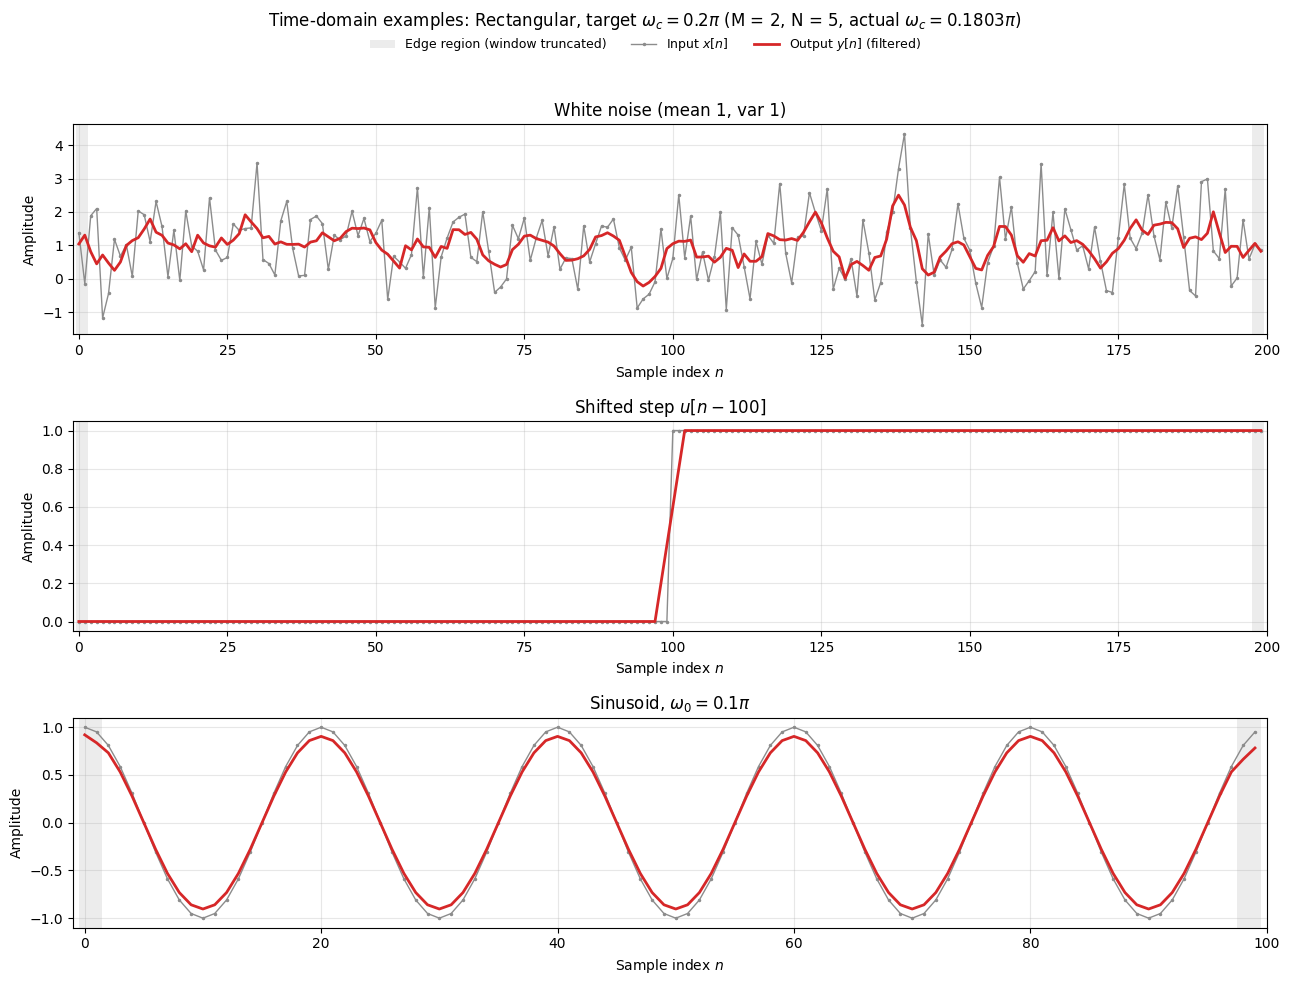

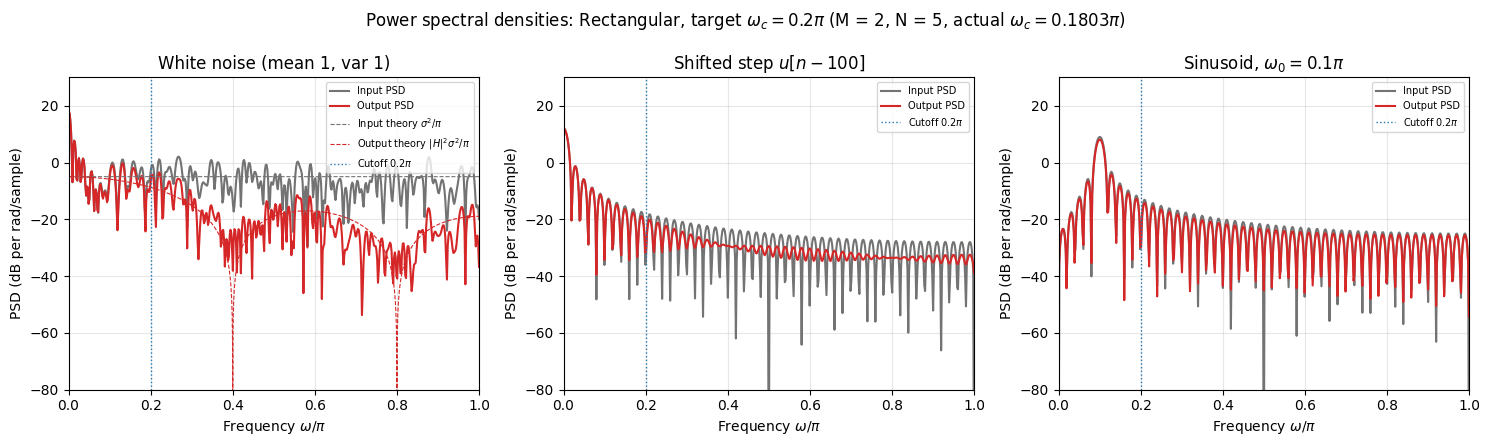

In [14]:
report_design("Rectangular", 0.2)

### Triangular (Bartlett)

#### Triangular, $\omega_c = 0.05\pi$

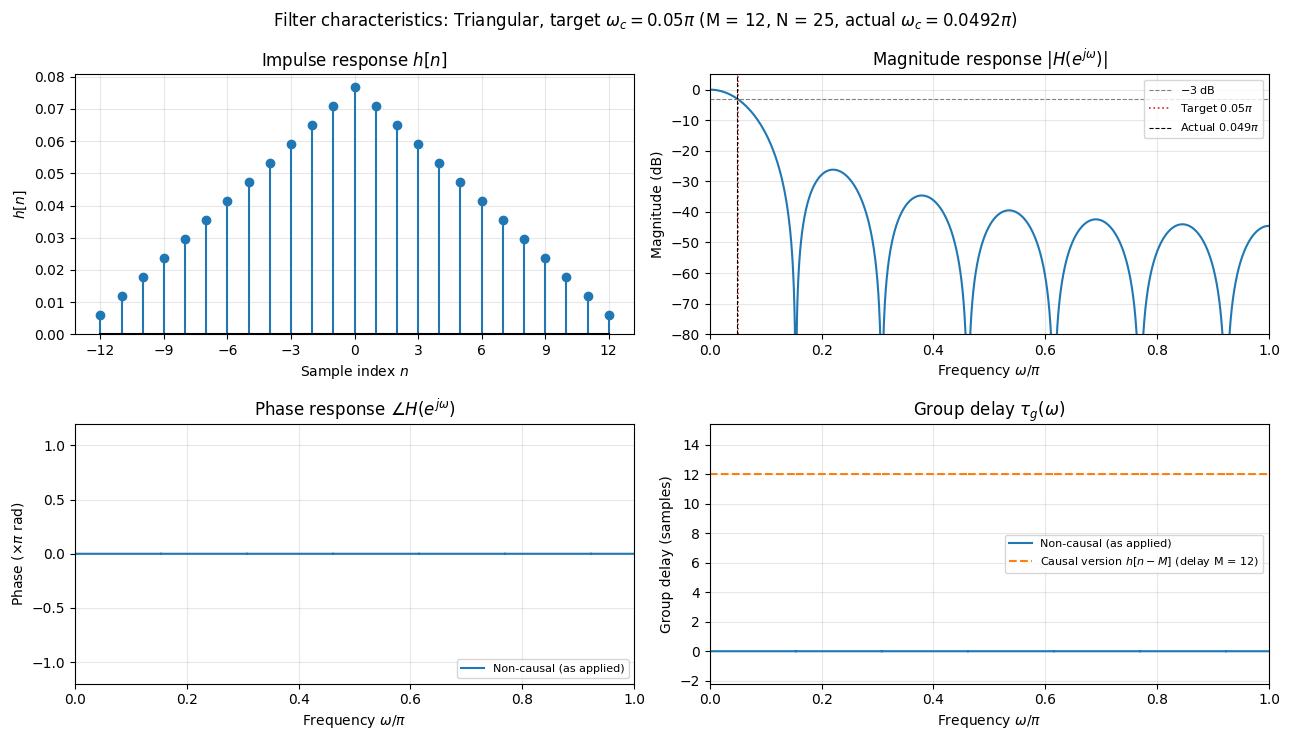

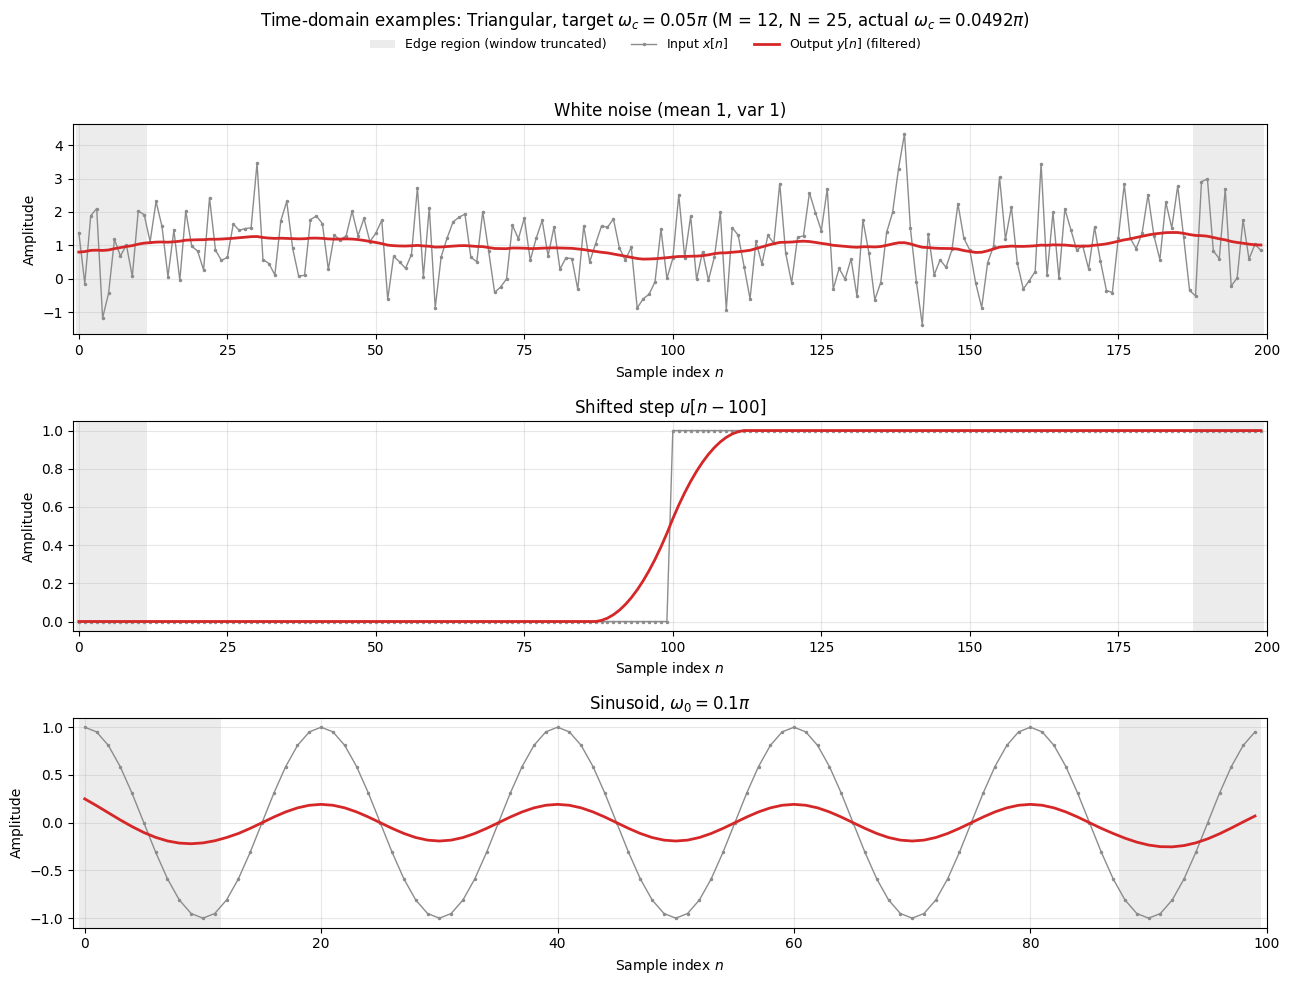

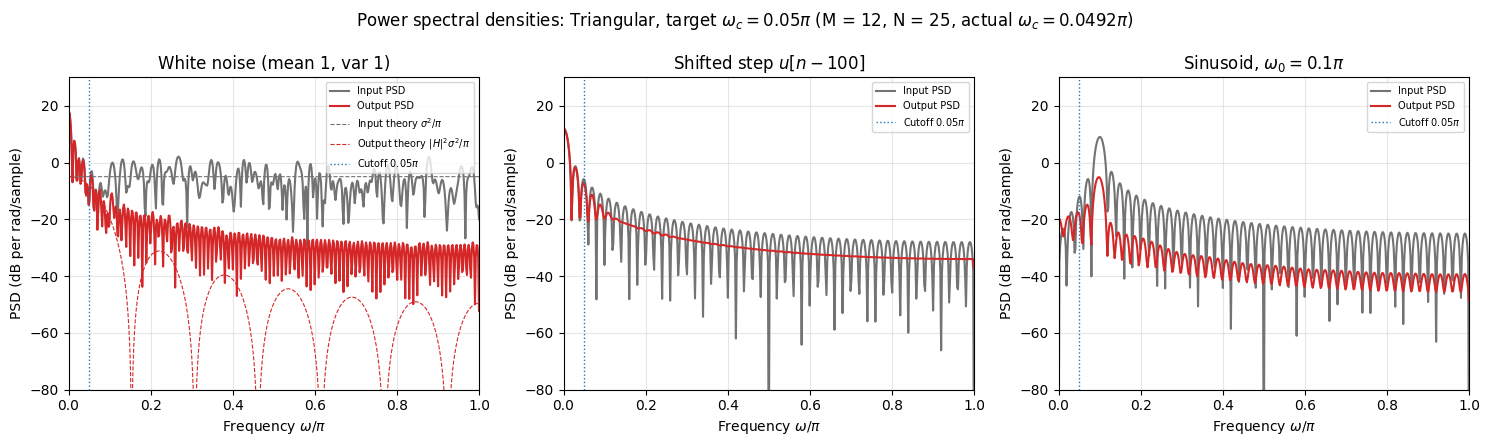

In [15]:
report_design("Triangular", 0.05)

#### Triangular, $\omega_c = 0.1\pi$

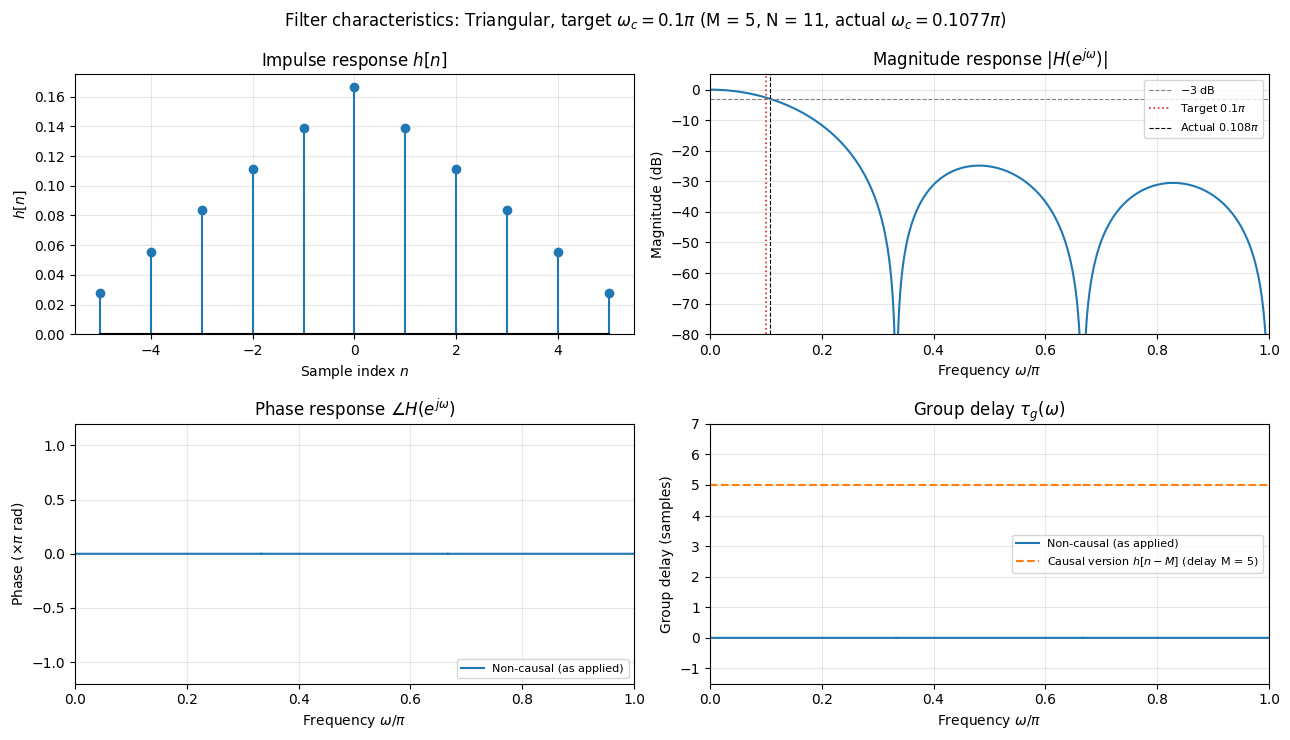

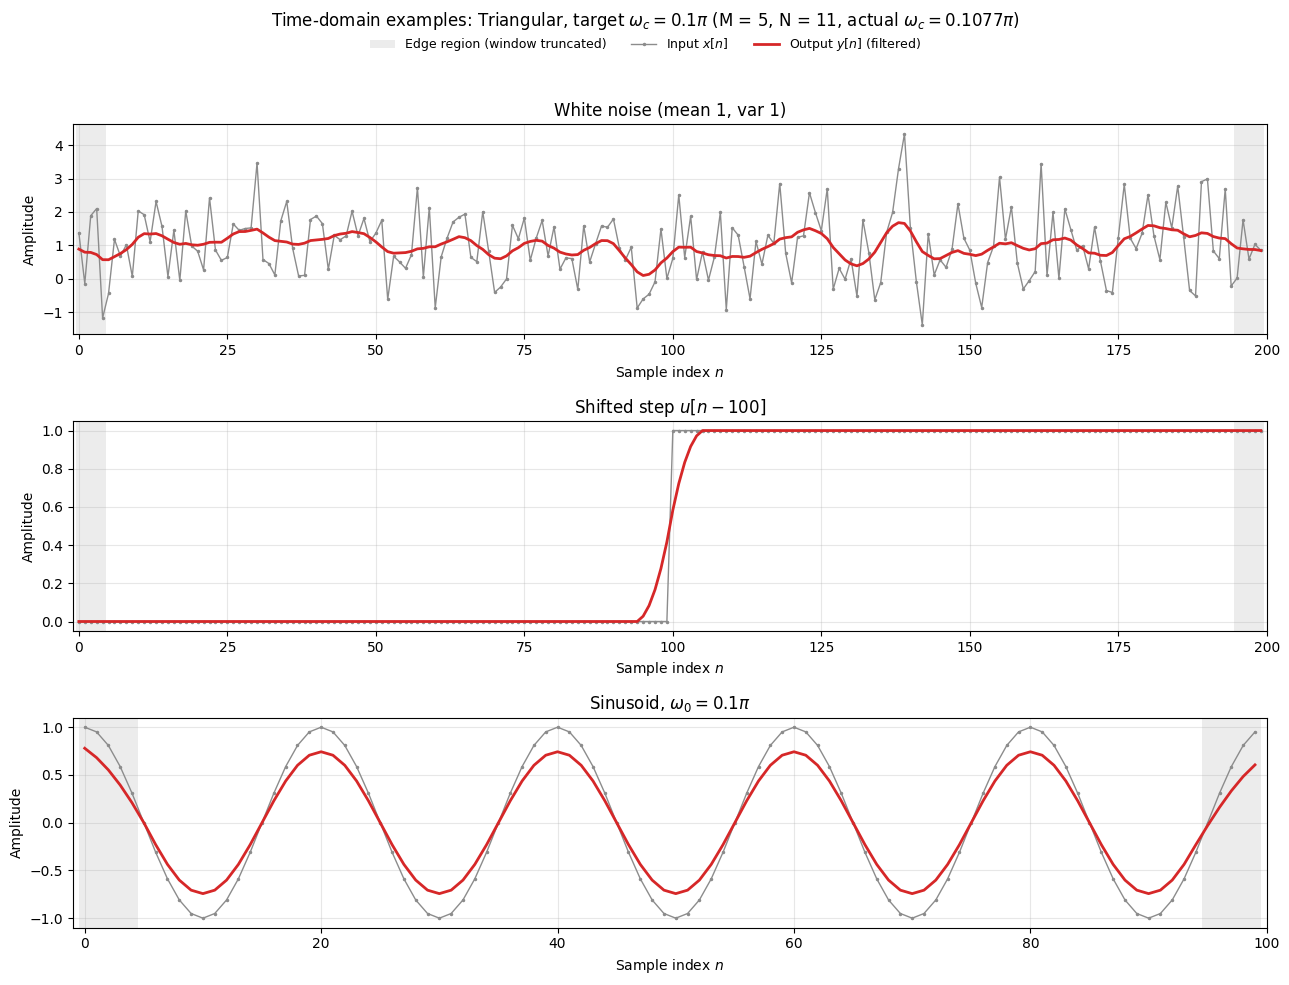

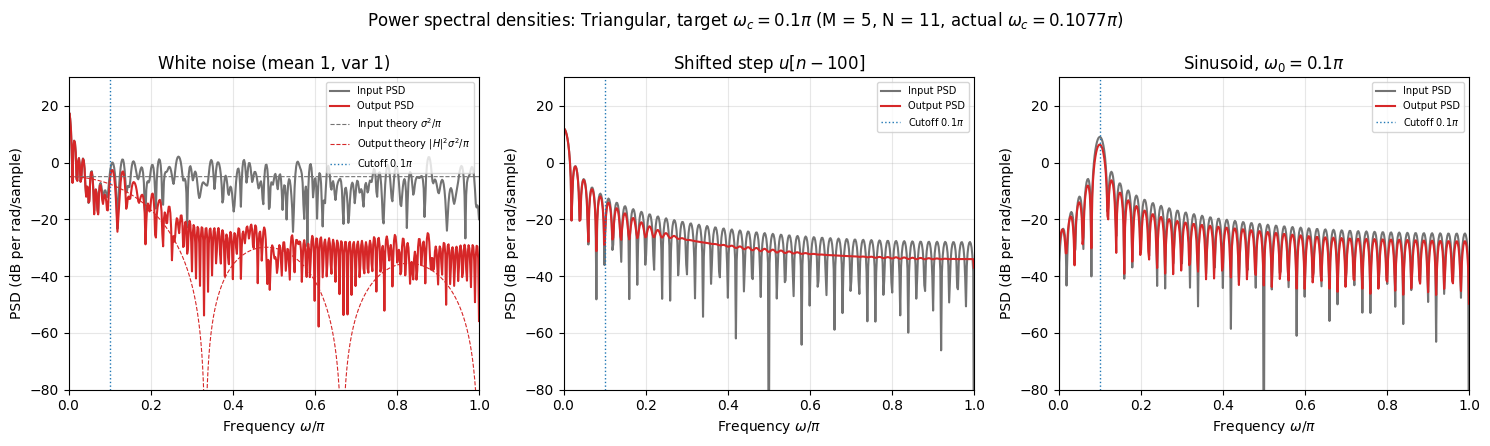

In [16]:
report_design("Triangular", 0.1)

#### Triangular, $\omega_c = 0.2\pi$

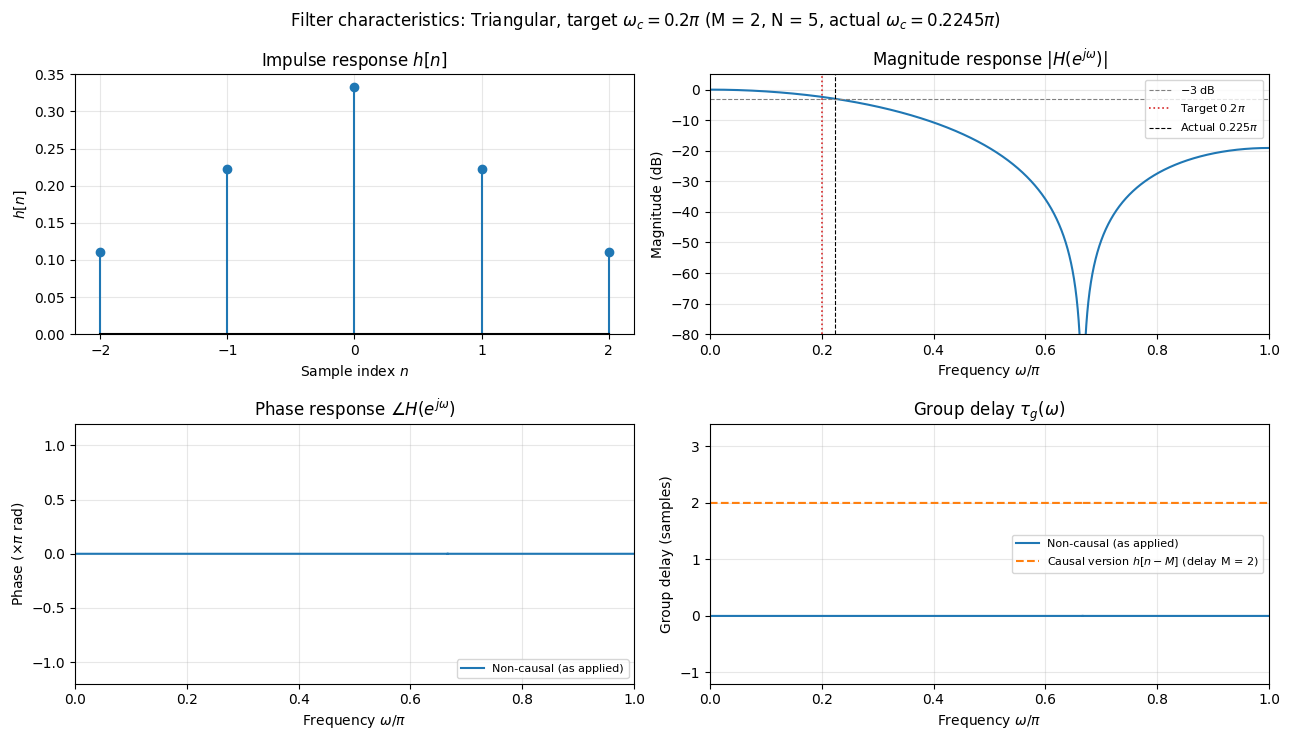

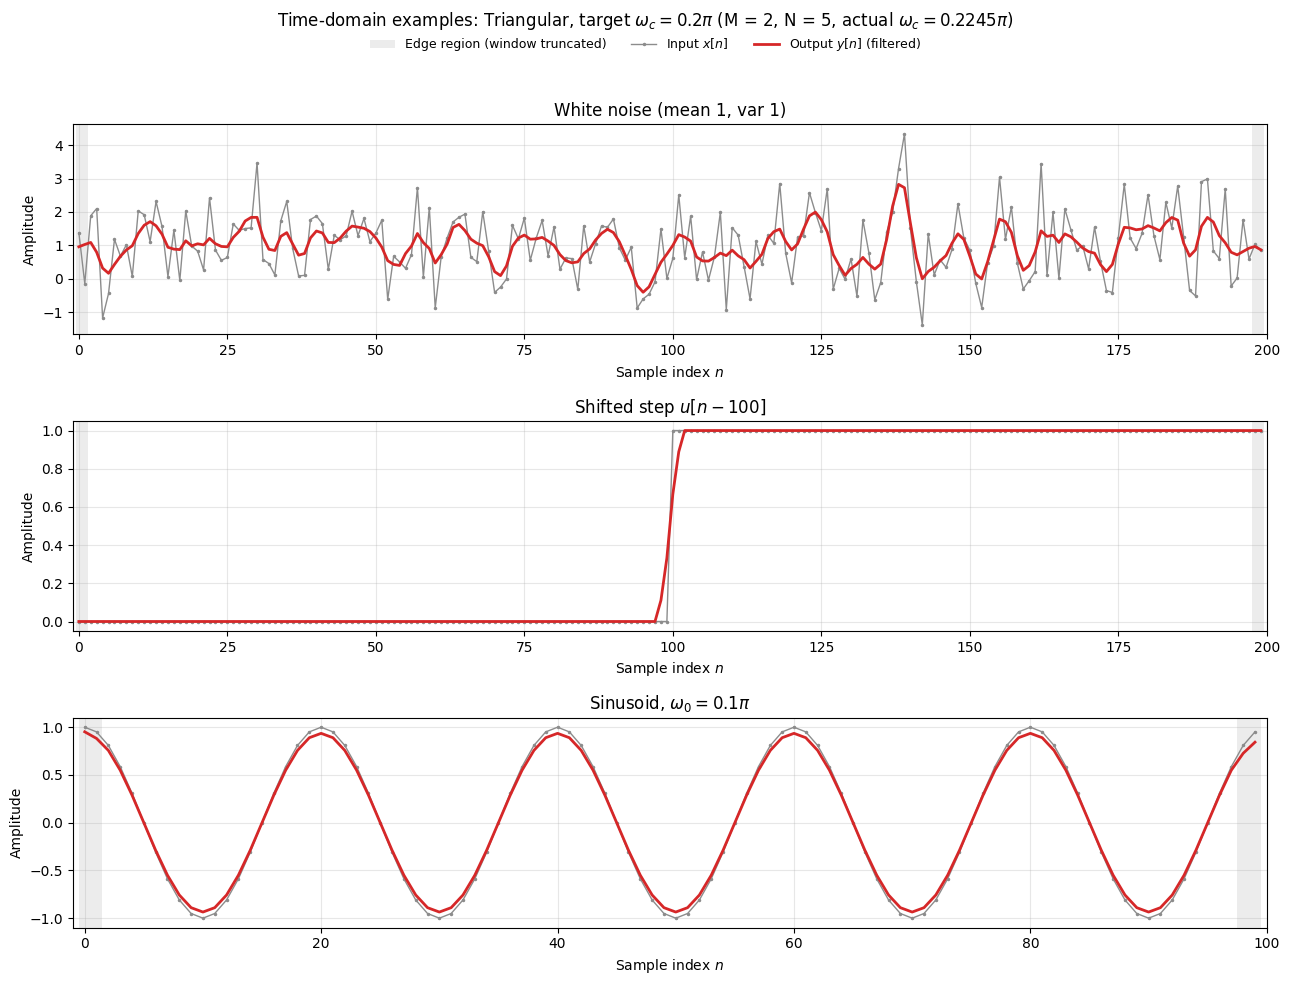

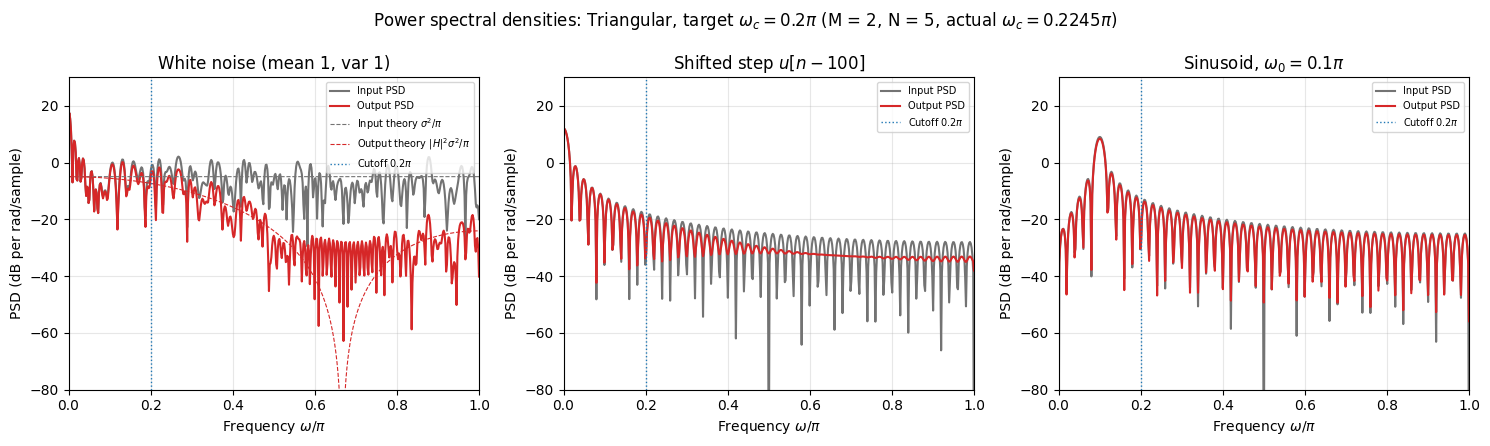

In [17]:
report_design("Triangular", 0.2)

### Binomial

#### Binomial, $\omega_c = 0.05\pi$

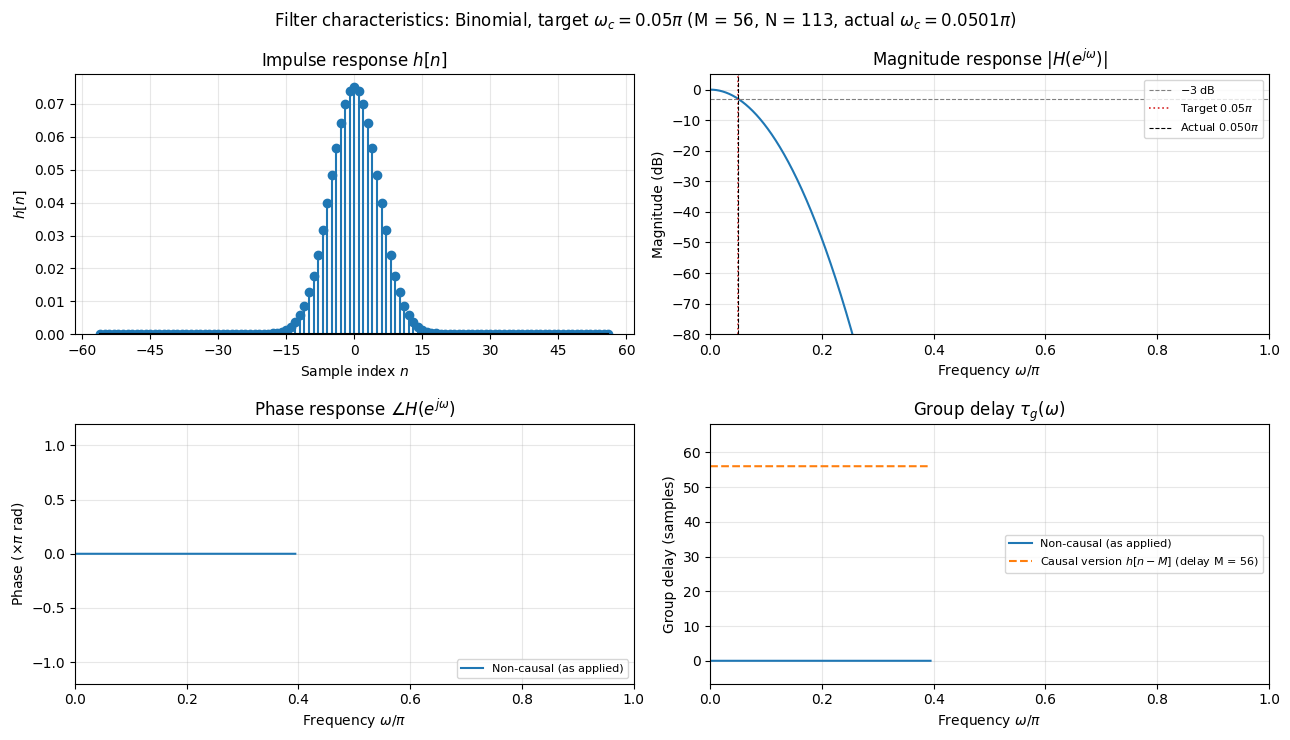

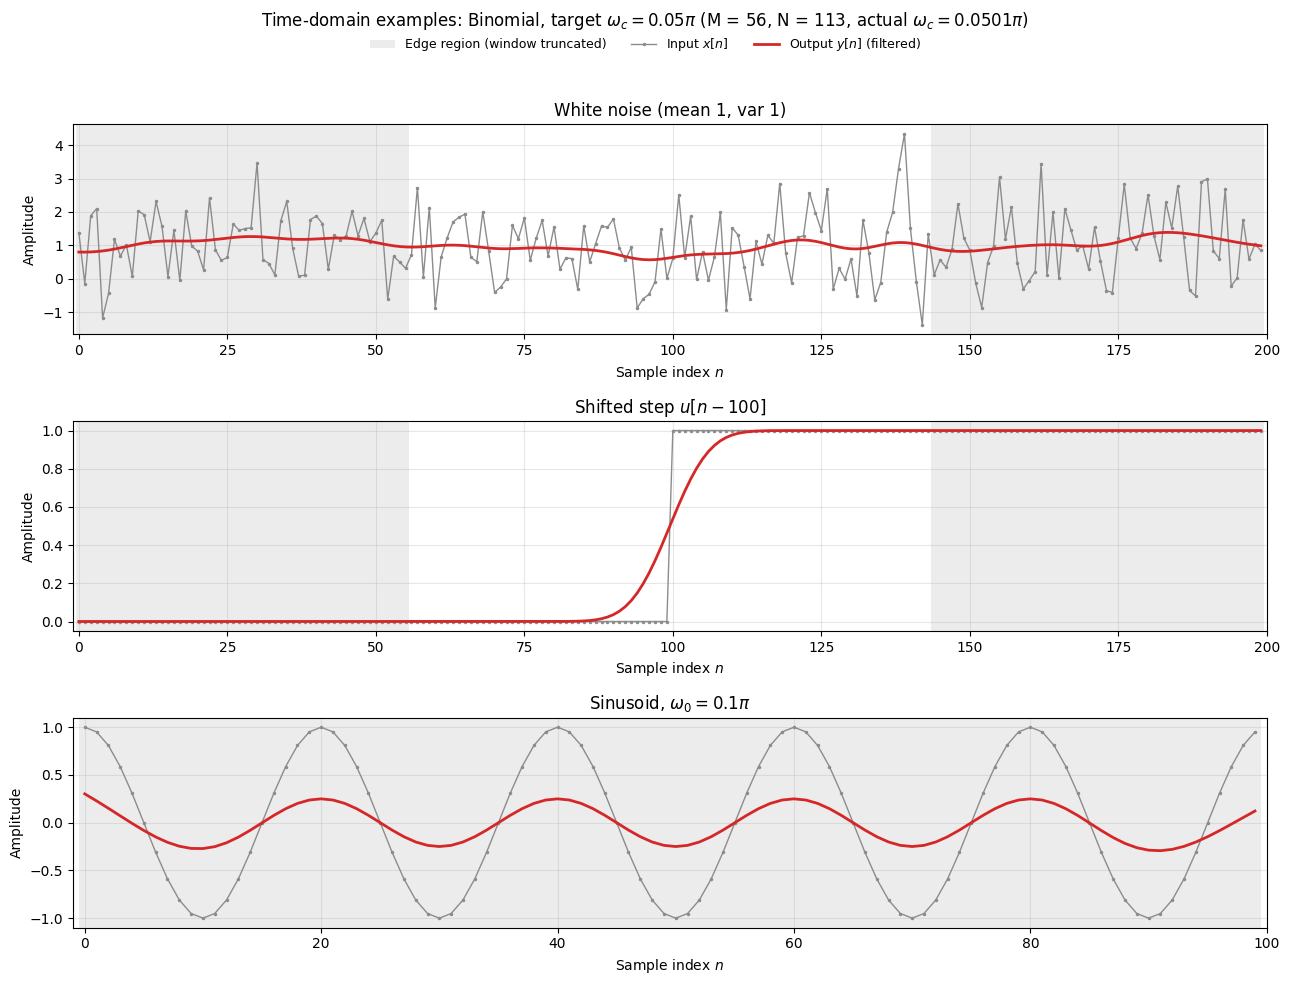

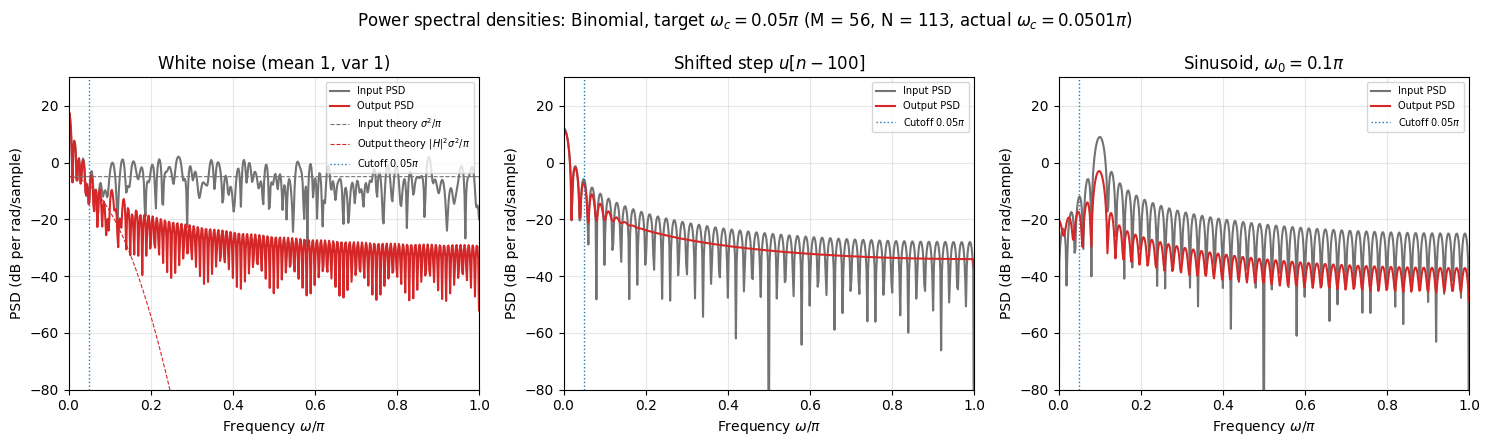

In [18]:
report_design("Binomial", 0.05)

#### Binomial, $\omega_c = 0.1\pi$

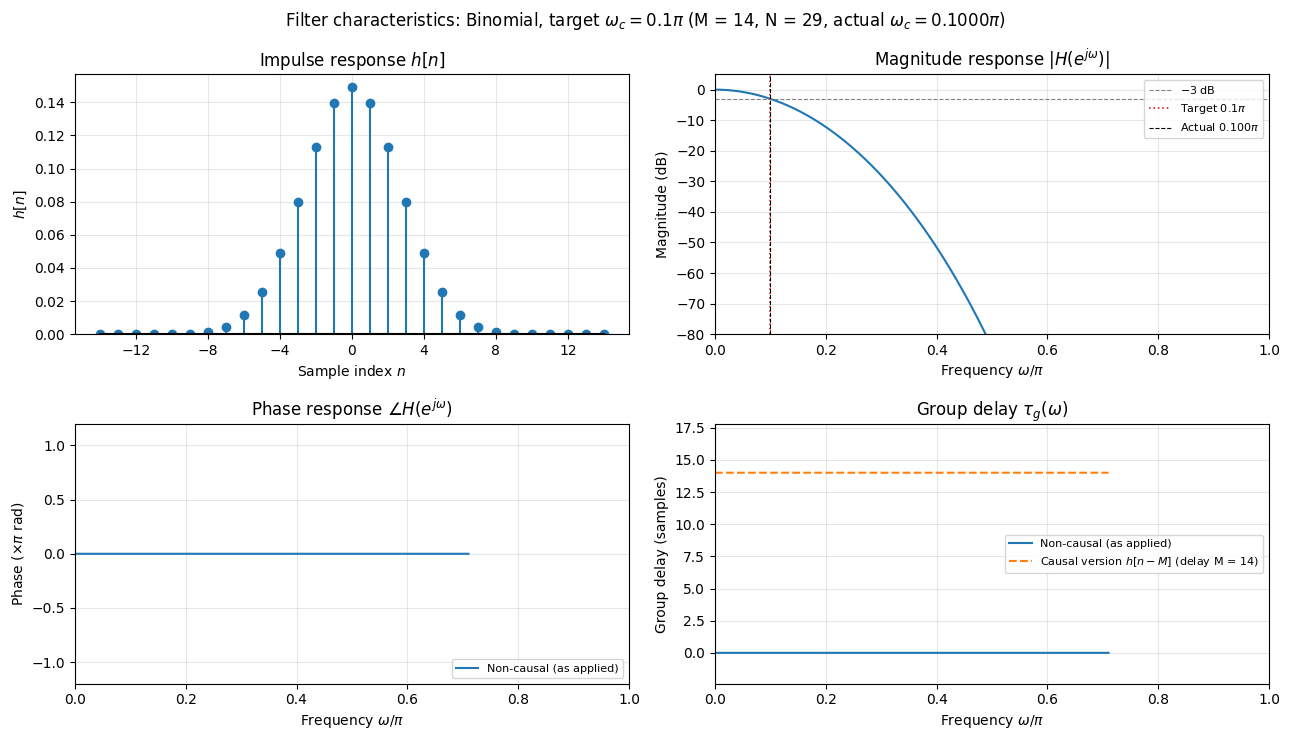

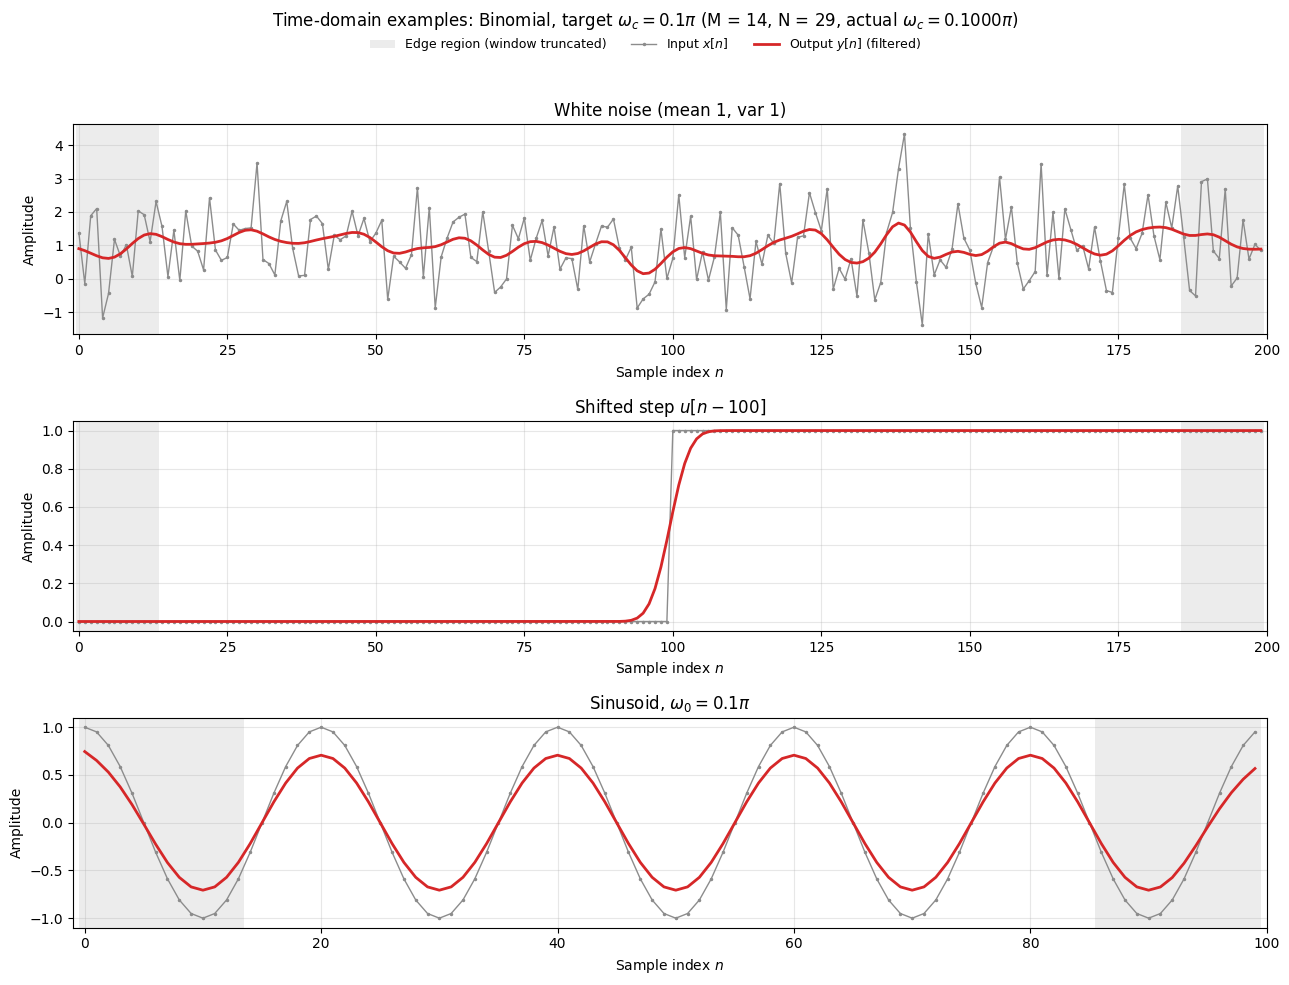

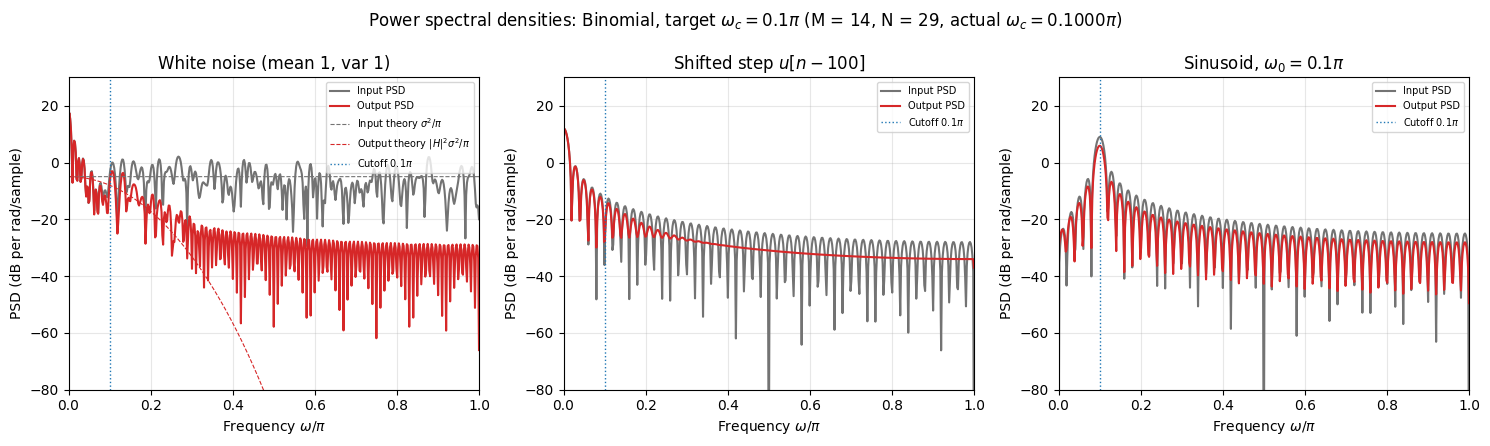

In [19]:
report_design("Binomial", 0.1)

#### Binomial, $\omega_c = 0.2\pi$

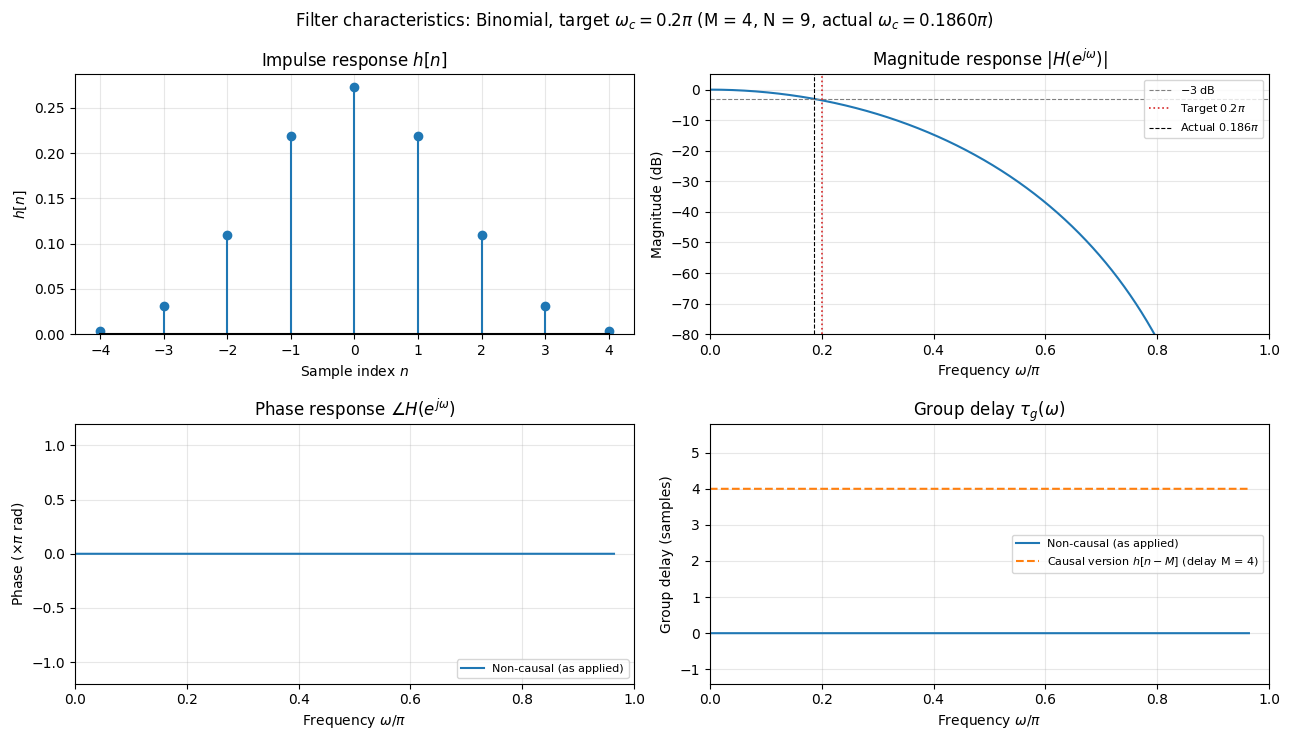

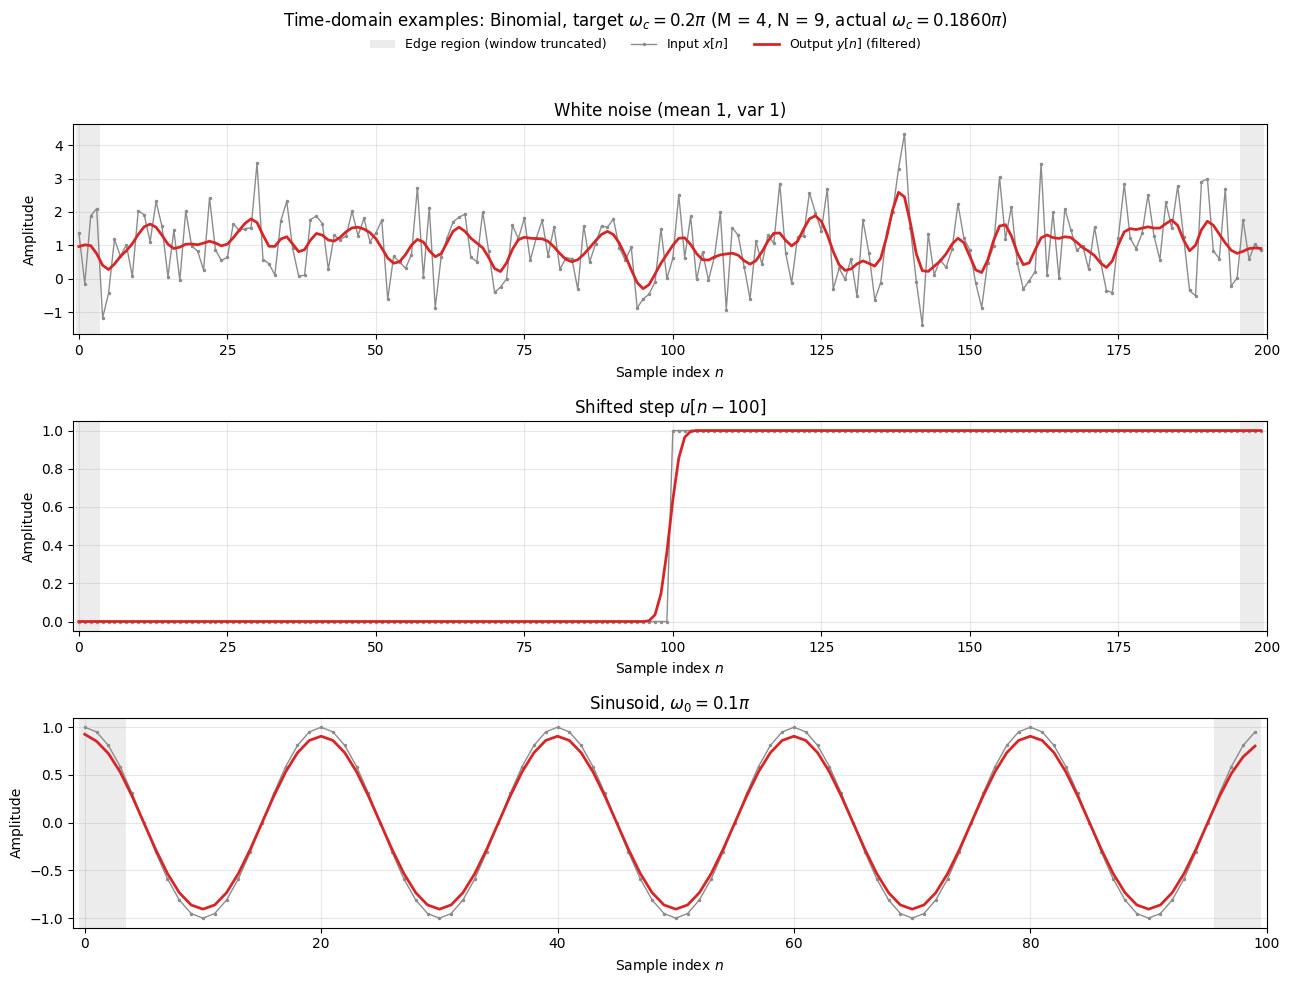

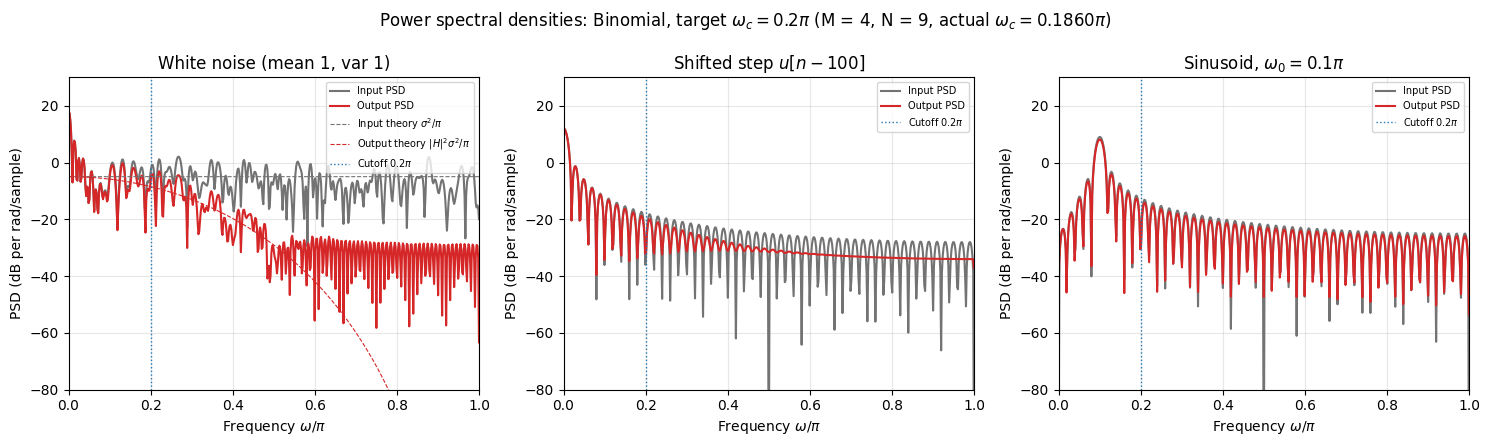

In [20]:
report_design("Binomial", 0.2)

## Problem 3: Explain how this type of filter might be used as a highpass filter. Provide an example with the following:
* Magnitude response
* Phase response
* Group delay
* Impulse response
* Time domain example of the filter applied to a white noise, signal with 200 samples
* Power spectral density plot of the input signal
  * _**Please use the periodogram method or an appropriately scaled FFT to compute the PSD on all signals.**_
* Power spectral density plot of the output signal
  * _**Please use the periodogram method or an appropriately scaled FFT to compute the PSD on all signals.**_

### Idea: subtract the smoothed signal from the original

A smoothing filter keeps the slowly varying part of a signal (the trend). Subtracting that trend from the original leaves only the fast-varying part. In filter terms, the highpass filter is the **complement** of the lowpass filter:
$$
y_{\text{hp}}[n] = x[n] - (h_{\text{lp}} * x)[n]
\quad\Longleftrightarrow\quad
h_{\text{hp}}[n] = \delta[n] - h_{\text{lp}}[n]
\quad\Longleftrightarrow\quad
H_{\text{hp}}(e^{j\omega}) = 1 - H_{\text{lp}}(e^{j\omega}).
$$
This is a standard construction, which Smith calls **spectral inversion** [1]. The lowpass filter and an "all-pass" path, whose impulse response is $\delta[n]$, run in parallel, and the lowpass output is subtracted from the original. Equivalently, flipping the sign of every lowpass tap and adding 1 to the center tap gives the highpass kernel, and its frequency response is the lowpass response flipped top for bottom [1]. Image processing uses the same idea to sharpen images [2].

**Properties inherited from the lowpass filter:**

- **Zero DC gain:** $H_{\text{hp}}(e^{j0}) = 1 - \sum_n h_{\text{lp}}[n] = 1 - 1 = 0$. The unit-DC-gain normalization from Problem 1 is exactly what makes the highpass reject DC completely, so any constant offset (such as the mean of 1 in the test noise) is removed. Equivalently, the highpass taps sum to zero [2].
- **Even symmetry and zero phase:** $\delta[n]$ and $h_{\text{lp}}[n]$ are both even, so $h_{\text{hp}}[n]$ is even and $H_{\text{hp}}(e^{j\omega})$ is real [3]. Because $H_{\text{lp}}(e^{j\omega}) \le 1$ for every non-negative filter (the taps sum to 1, so $|H| \le \sum |h| = 1$), $H_{\text{hp}}(e^{j\omega}) = 1 - H_{\text{lp}}(e^{j\omega}) \ge 0$ at every frequency. The phase is therefore zero wherever $H_{\text{hp}} \ne 0$, and the group delay is zero (or a constant $M$ samples for the causal version) [3].
- **Same length:** $h_{\text{hp}}$ has the same $2M+1$ taps as $h_{\text{lp}}$. Only the center tap changes, to $1 - h_{\text{lp}}[0]$ [1].
- **Not non-negative:** $h_{\text{hp}}[0] = 1 - h_{\text{lp}}[0] > 0$, and every other tap is $-h_{\text{lp}}[n] \le 0$. The taps sum to 0, as a filter with zero DC gain must.

**Cutoff.** For the highpass filter, the $-3$ dB cutoff is the frequency where $H_{\text{hp}}$ *rises* to $1/\sqrt{2}$, which is where the lowpass filter has fallen to $1 - 1/\sqrt{2} \approx 0.293$ ($-10.7$ dB). So a highpass cutoff of $\omega_c$ needs a lowpass filter whose own $-3$ dB cutoff is below $\omega_c$, and therefore a somewhat longer filter.

**Edge handling.** I compute the output as $y_{\text{hp}} = x - \text{apply\_filter}(x, h_{\text{lp}})$, using the same normalized convolution as in Problem 2. Because the lowpass part preserves DC exactly at the edges, the highpass output still rejects DC at the edges, so the output does not jump at the ends of the record. (Zero-padding would make the smoothed trend sag toward 0 at the ends, and the highpass output would then show a spurious jump of about 1 at each end of the mean-1 noise.)

**References**

[1] S. W. Smith, *The Scientist and Engineer's Guide to Digital Signal Processing*, 2nd ed. San Diego, CA: California Technical Publishing, 1999, ch. 14, "High-Pass, Band-Pass and Band-Reject Filters," Figs. 14-5 and 14-6. [Online]. Available: https://www.dspguide.com/ch14/5.htm

[2] R. Wang, "Sharpening," E161 lecture notes, Harvey Mudd College. [Online]. Available: https://pages.hmc.edu/ruye/e161/lectures/gradient/node1.html

[3] A. V. Oppenheim and R. W. Schafer, *Discrete-Time Signal Processing*, 3rd ed. Upper Saddle River, NJ: Prentice Hall, 2009, Sec. 5.7 (systems with generalized linear phase).

### Choosing the lowpass prototype

For a target highpass cutoff of $\omega_c = 0.1\pi$, I find the length of each Problem 1 filter whose complement comes closest to that cutoff, and compare the three highpass magnitude responses.

Prototype       M    N  HP cutoff  Max gain
Rectangular     7   15    0.1008π    +1.73 dB
Triangular     11   23    0.0957π    +0.00 dB
Binomial       50  101    0.0996π    +0.00 dB


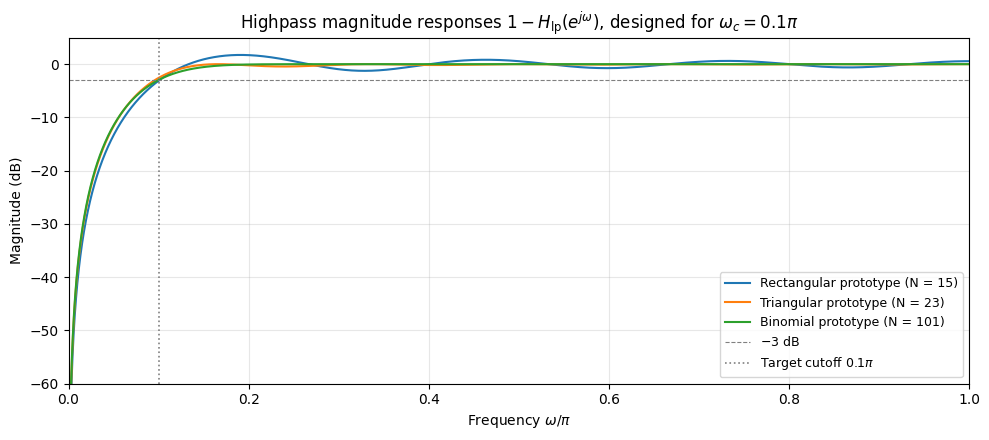

In [21]:
def highpass_from_lowpass(h_lp):
    # h_hp[n] = delta[n] - h_lp[n], with both centered at n = 0
    M = (len(h_lp) - 1) // 2
    h_hp = -h_lp.copy()
    h_hp[M] += 1.0
    return h_hp


def cutoff_3dB_highpass(filter_fn, M, n_grid=8192):
    # First frequency (rad/sample) where 1 - H_lp rises to 1/sqrt(2).
    _, h = filter_fn(M)
    level = 1 / np.sqrt(2)
    w = np.linspace(0, np.pi, n_grid)
    Hhp = 1 - amplitude_response(h, M, w)
    i = np.argmax(Hhp >= level)
    f = lambda x: 1 - amplitude_response(h, M, np.array([x]))[0] - level
    return brentq(f, w[i - 1], w[i])


hp_target = 0.1 * np.pi
hp_design = {}
for name, fn in filters.items():
    wcs = np.array([cutoff_3dB_highpass(fn, M) for M in M_range])
    i = np.argmin(np.abs(wcs - hp_target))
    hp_design[name] = (M_range[i], wcs[i])

fig, ax = plt.subplots(figsize=(10, 4.5))
print(f"{'Prototype':12s} {'M':>4s} {'N':>4s} {'HP cutoff':>10s} {'Max gain':>9s}")
for name, fn in filters.items():
    M, wc = hp_design[name]
    _, h = fn(M)
    Hhp = 1 - amplitude_response(h, M, w_grid)
    print(f"{name:12s} {M:4d} {2*M+1:4d} {wc/np.pi:9.4f}π {20*np.log10(Hhp.max()):+8.2f} dB")
    ax.plot(w_grid / np.pi, 20 * np.log10(np.maximum(Hhp, 1e-6)), color=colors[name],
            label=f"{name} prototype (N = {2*M+1})")
ax.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
ax.axvline(0.1, color="gray", ls=":", lw=1.2, label="Target cutoff $0.1\\pi$")
ax.set_title("Highpass magnitude responses $1 - H_{\\mathrm{lp}}(e^{j\\omega})$, designed for $\\omega_c = 0.1\\pi$")
ax.set_xlabel("Frequency $\\omega/\\pi$")
ax.set_ylabel("Magnitude (dB)")
ax.set_xlim(0, 1)
ax.set_ylim(-60, 5)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="lower right")
plt.tight_layout()
plt.show()

**Choice: triangular prototype.** The three complements behave differently above the cutoff:

- **Rectangular:** its lowpass sidelobes go negative, so $1 - H_{\text{lp}}$ rises *above* 1. The passband ripples, amplifying some frequencies by up to about $+1.7$ dB.
- **Triangular:** $H_{\text{lp}}(e^{j\omega}) \ge 0$ (a squared Dirichlet kernel), so $0 \le H_{\text{hp}} \le 1$. The passband never exceeds unity gain, ripple is small, and the filter is short.
- **Binomial:** the cleanest response (monotonic, no ripple at all), but its gradual roll-off means it needs about $4\times$ as many taps for the same cutoff. That makes the edge regions half of a 200-sample record.

The triangular prototype is the best balance of passband flatness and length here, so I use it for the detailed example below.

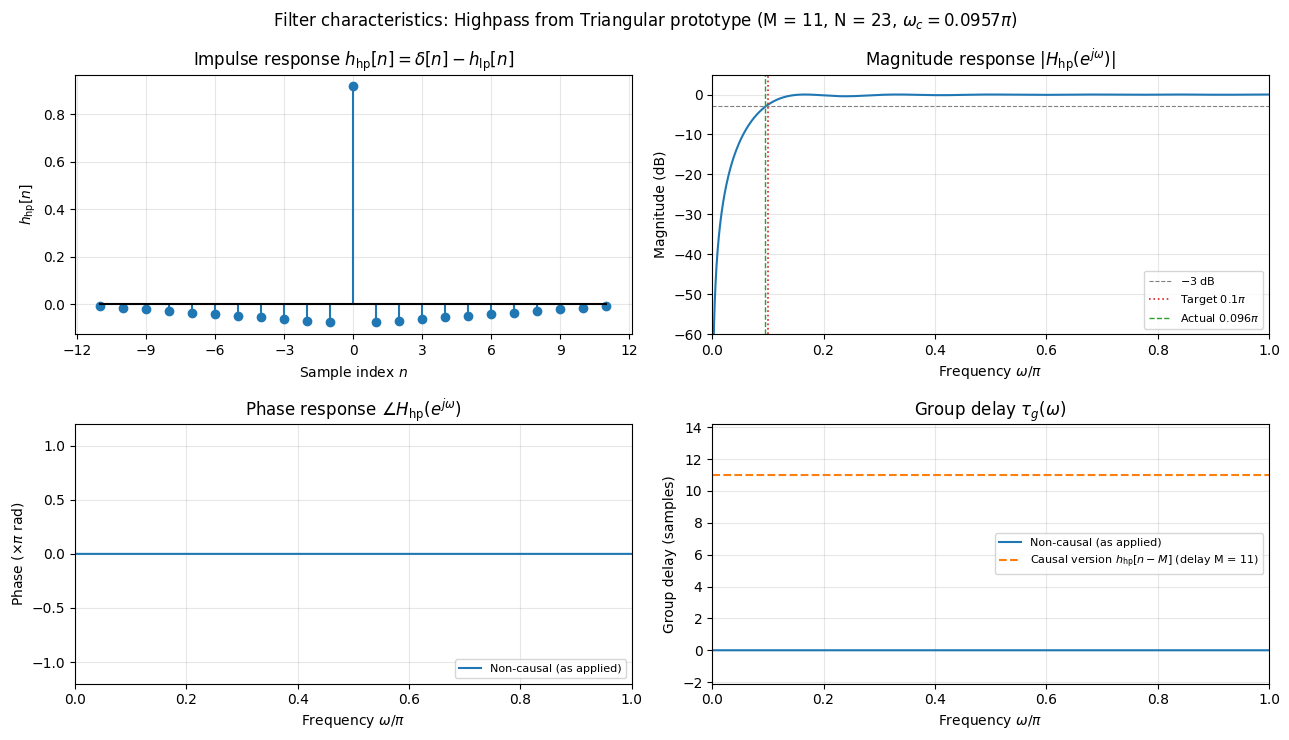

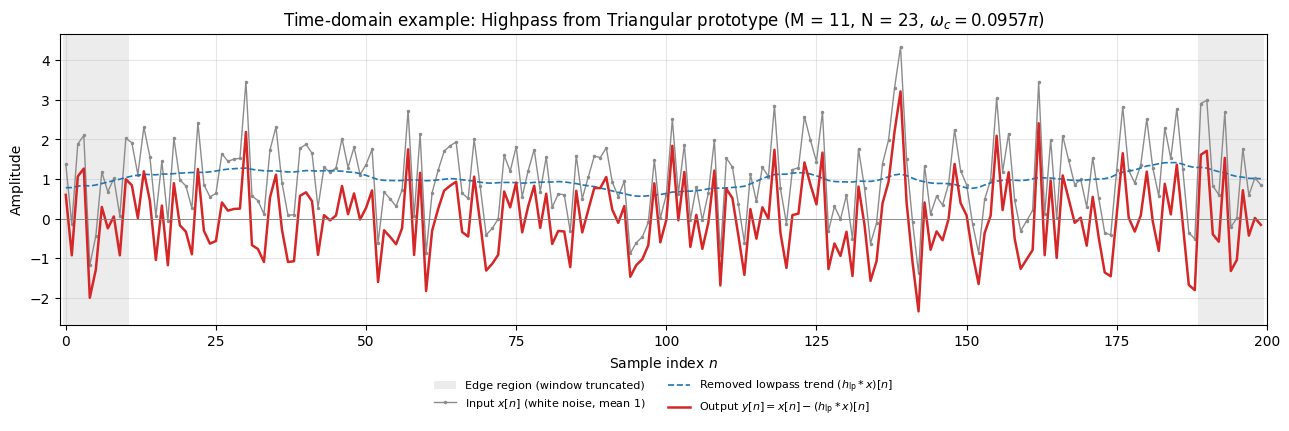

Input : mean = +1.000, variance = 1.000
Output: mean = -0.001, variance = 0.918 (theory for white input: input variance x sum(h_hp^2) = 0.889)


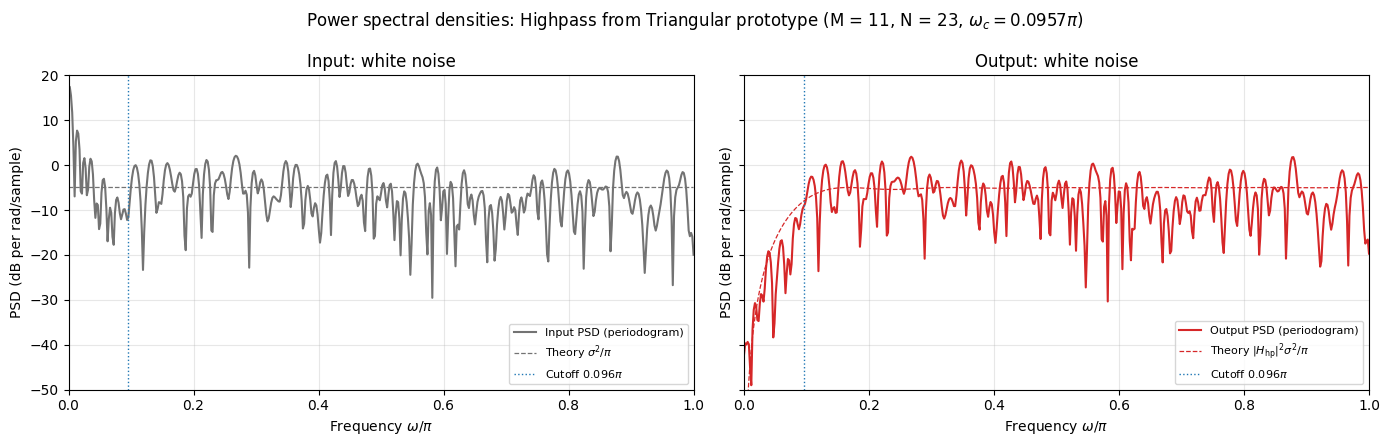

In [22]:
def report_highpass(name):
    fn = filters[name]
    M, wc = hp_design[name]
    n, h_lp = fn(M)
    h_hp = highpass_from_lowpass(h_lp)
    tag = (f"Highpass from {name} prototype (M = {M}, N = {2*M+1}, "
           f"$\\omega_c = {wc/np.pi:.4f}\\pi$)")

    # ---------- Figure 1: filter characteristics ----------
    Hhp = 1 - amplitude_response(h_lp, M, w_grid)           # real (zero-phase) response
    mag_db = 20 * np.log10(np.maximum(np.abs(Hhp), 1e-6))
    tiny = np.abs(Hhp) < 1e-10                              # phase undefined where H = 0
    phase = np.where(Hhp < 0, np.pi, 0.0)
    phase[tiny] = np.nan
    with warnings.catch_warnings(), np.errstate(all="ignore"):
        warnings.simplefilter("ignore")
        _, gd_causal = group_delay((h_hp, [1.0]), w=w_grid)
    gd_causal[np.abs(Hhp) < 1e-6] = np.nan                  # unreliable near the DC null
    gd_noncausal = gd_causal - M

    fig, ax = plt.subplots(2, 2, figsize=(13, 7.5))
    fig.suptitle(f"Filter characteristics: {tag}", fontsize=12)

    a = ax[0, 0]
    a.stem(n, h_hp, basefmt="k-")
    a.set_title("Impulse response $h_{\\mathrm{hp}}[n] = \\delta[n] - h_{\\mathrm{lp}}[n]$")
    a.set_xlabel("Sample index $n$")
    a.set_ylabel("$h_{\\mathrm{hp}}[n]$")
    a.xaxis.set_major_locator(MaxNLocator(integer=True))

    a = ax[0, 1]
    a.plot(w_grid / np.pi, mag_db, color="C0")
    a.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
    a.axvline(0.1, color="C3", ls=":", lw=1.2, label="Target $0.1\\pi$")
    a.axvline(wc / np.pi, color="C2", ls="--", lw=1.0, label=f"Actual {wc/np.pi:.3f}$\\pi$")
    a.set_title("Magnitude response $|H_{\\mathrm{hp}}(e^{j\\omega})|$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Magnitude (dB)")
    a.set_ylim(-60, 5)
    a.legend(fontsize=8, loc="lower right")

    a = ax[1, 0]
    a.plot(w_grid / np.pi, phase / np.pi, color="C0", label="Non-causal (as applied)")
    a.set_title("Phase response $\\angle H_{\\mathrm{hp}}(e^{j\\omega})$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Phase ($\\times\\pi$ rad)")
    a.set_ylim(-1.2, 1.2)
    a.legend(fontsize=8, loc="lower right")

    a = ax[1, 1]
    a.plot(w_grid / np.pi, gd_noncausal, color="C0", label="Non-causal (as applied)")
    a.plot(w_grid / np.pi, gd_causal, color="C1", ls="--",
           label=f"Causal version $h_{{\\mathrm{{hp}}}}[n-M]$ (delay M = {M})")
    a.set_title("Group delay $\\tau_g(\\omega)$")
    a.set_xlabel("Frequency $\\omega/\\pi$")
    a.set_ylabel("Group delay (samples)")
    a.set_ylim(-0.1 * M - 1, 1.2 * M + 1)
    a.legend(fontsize=8, loc="center right")

    for a in ax.flat:
        a.grid(True, alpha=0.3)
    for a in [ax[0, 1], ax[1, 0], ax[1, 1]]:
        a.set_xlim(0, 1)
    plt.tight_layout()
    plt.show()

    # ---------- Figure 2: time-domain example (white noise) ----------
    x = x_noise
    trend = apply_filter(x, h_lp)       # lowpass part, normalized convolution at edges
    y = x - trend                       # highpass output
    k = np.arange(len(x))

    fig, ax = plt.subplots(figsize=(13, 4.5))
    shade_edges(ax, len(x), M)
    ax.plot(k, x, color="0.55", lw=1.0, marker=".", ms=3, label="Input $x[n]$ (white noise, mean 1)")
    ax.plot(k, trend, color="C0", lw=1.2, ls="--", label="Removed lowpass trend $(h_{\\mathrm{lp}} * x)[n]$")
    ax.plot(k, y, color="C3", lw=1.8, label="Output $y[n] = x[n] - (h_{\\mathrm{lp}} * x)[n]$")
    ax.axhline(0, color="gray", lw=0.6)
    ax.set_title(f"Time-domain example: {tag}")
    ax.set_xlabel("Sample index $n$")
    ax.set_ylabel("Amplitude")
    ax.set_xlim(-1, len(x))
    ax.grid(True, alpha=0.3)
    ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.15), ncol=2, frameon=False)
    plt.tight_layout()
    plt.show()

    var_theory = np.var(x, ddof=1) * np.sum(h_hp ** 2)
    print(f"Input : mean = {x.mean():+.3f}, variance = {np.var(x, ddof=1):.3f}")
    print(f"Output: mean = {y.mean():+.3f}, variance = {np.var(y, ddof=1):.3f} "
          f"(theory for white input: input variance x sum(h_hp^2) = {var_theory:.3f})")

    # ---------- Figure 3: PSDs of input and output ----------
    f_in, P_in = psd_db(x)
    f_out, P_out = psd_db(y)
    fig, ax = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
    fig.suptitle(f"Power spectral densities: {tag}", fontsize=12)
    for a, (P, col, lab) in zip(ax, [(P_in, "0.45", "Input"), (P_out, "C3", "Output")]):
        a.plot(f_in / np.pi, P, color=col, label=f"{lab} PSD (periodogram)")
        theory = 1 / np.pi if lab == "Input" else Hhp ** 2 / np.pi
        a.plot(w_grid / np.pi, 10 * np.log10(np.maximum(theory * np.ones_like(w_grid), 1e-12)),
               color=col, ls="--", lw=0.9,
               label="Theory $\\sigma^2/\\pi$" if lab == "Input" else "Theory $|H_{\\mathrm{hp}}|^2\\sigma^2/\\pi$")
        a.axvline(wc / np.pi, color="C0", ls=":", lw=1.0, label=f"Cutoff {wc/np.pi:.3f}$\\pi$")
        a.set_title(f"{lab}: white noise")
        a.set_xlabel("Frequency $\\omega/\\pi$")
        a.set_ylabel("PSD (dB per rad/sample)")
        a.set_xlim(0, 1)
        a.set_ylim(-50, 20)
        a.grid(True, alpha=0.3)
        a.legend(fontsize=8, loc="lower right")
    plt.tight_layout()
    plt.show()


report_highpass("Triangular")

**Observations.**

- The input's mean of 1 shows up as the large peak at $\omega = 0$ in the input PSD. The highpass output has a mean near 0, and its PSD drops steeply toward DC, confirming $H_{\text{hp}}(e^{j0}) = 0$.
- Above the cutoff the output PSD matches the input, since $H_{\text{hp}} \approx 1$ there. The filter removes the slow wander and passes the sample-to-sample fluctuations unchanged.
- The output variance is slightly below the input variance, because only the low-frequency band, a small fraction of the total power, is removed.
- The phase is zero, so the output is aligned in time with the input. A spike in the input appears at the same index in the output.

## Problem 4: Explain what you think the best way is to handle edge conditions with this filter? Provide good, defensible rationale for your proposal. There is no single right answer.

### The problem

A non-causal filter of length $2M+1$ needs $M$ input samples on **each side** of the output sample. For the first and last $M$ outputs, some of those samples don't exist. Any edge method is really an assumption about the missing samples, or a decision not to make one.

### Candidate methods

| Method | What it assumes about the missing samples |
|---|---|
| Zero padding | They are 0 |
| Edge replication | They equal the end sample, $x[0]$ or $x[L-1]$ |
| Even reflection | The signal mirrors about the end sample: $x[-k] = x[k]$ |
| Odd reflection | The signal continues its local trend: $x[-k] = 2x[0] - x[k]$ |
| Periodic extension | The signal repeats: $x[-k] = x[L-k]$ |
| Normalized convolution | Nothing. It uses only the samples that exist and rescales the truncated filter so its taps sum to 1 |
| Discard ("valid") | Nothing. It drops the $M$ outputs at each end |

Normalized convolution (used in Problems 2 and 3) computes
$$
y[n] = \frac{\sum_{k} h[k]\,x[n-k]}{\sum_{k} h[k]}, \qquad \text{both sums over } k \text{ with } 0 \le n-k \le L-1,
$$
which amounts to a different, truncated-and-renormalized filter at each edge sample. Each output is still a weighted average of real samples with weights summing to 1.

### How I compare them

I use the triangular filter designed for $\omega_c = 0.05\pi$ ($M = 12$, $N = 25$), long enough for edge effects to be clearly visible, and three tests:

1. **The shifted step $u[n-100]$** from Problem 2, a signal whose two ends have different levels.
  * **What it probes:** methods that make an assumption about the far end of the signal. The step is 0 at the left end and 1 at the right end. A method that’s fine at one end can fail at the other.
2. **Monte Carlo on mean-1, variance-1 white noise** (4000 realizations). The ideal smoothed output is the constant 1, so I measure **bias** (does the method pull the estimate away from the true level?) and **RMSE** (bias and noise combined) at each distance from the edge.
  * **What it probes:** This test exposes a cost that the step and ramp tests can’t, because those signals have no noise. Some methods reuse a single noisy sample many times
3. **A noise-free ramp** $x[n] = 0.02\,n$. A symmetric filter with unit DC gain reproduces a straight line exactly in the interior, so any output error comes from the edge method alone. This tests how each method handles a trend at the boundary.
  * **What it probes:** how each method handles a trend at the boundary, with nothing else mixed in.

In [23]:
# ---- Edge-handling methods (all return an output the same length as x) ----
def filter_padded(x, h, mode, **kw):
    # Extend x by M samples on each side, then keep only the fully overlapped outputs.
    M = (len(h) - 1) // 2
    return np.convolve(np.pad(x, M, mode=mode, **kw), h, mode="valid")


edge_methods = {
    "Zero padding":           lambda x, h: filter_padded(x, h, "constant"),
    "Edge replication":       lambda x, h: filter_padded(x, h, "edge"),
    "Even reflection":        lambda x, h: filter_padded(x, h, "reflect"),
    "Odd reflection":         lambda x, h: filter_padded(x, h, "reflect", reflect_type="odd"),
    "Periodic extension":     lambda x, h: filter_padded(x, h, "wrap"),
    "Normalized convolution": apply_filter,
}
edge_styles = {
    "Zero padding":           dict(color="C0", lw=2.0, ls="--"),
    "Edge replication":       dict(color="C1", lw=1.2),
    "Even reflection":        dict(color="C2", lw=1.2),
    "Odd reflection":         dict(color="C4", lw=1.2),
    "Periodic extension":     dict(color="C5", lw=2.0, ls=":"),
    "Normalized convolution": dict(color="C3", lw=2.4),
}

# Filter used for the comparison: triangular, designed for 0.05*pi
edge_name, edge_target = "Triangular", 0.05
M_e = design[edge_name][min(design[edge_name], key=lambda t: abs(t - edge_target))]
_, h_e = filters[edge_name](M_e)
L_e = 200
print(f"Comparison filter: {edge_name}, M = {M_e}, N = {2*M_e+1}")

Comparison filter: Triangular, M = 12, N = 25


### Test 1: Shifted step

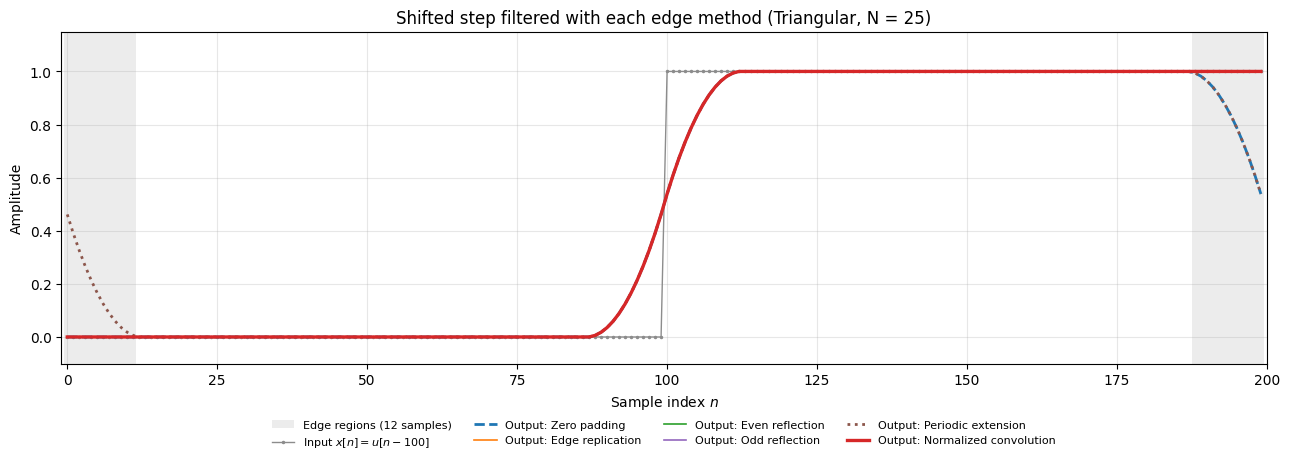

In [24]:
fig, ax = plt.subplots(figsize=(13, 4.8))
k = np.arange(L_e)
ax.axvspan(-0.5, M_e - 0.5, color="gray", alpha=0.15, lw=0)
ax.axvspan(L_e - M_e - 0.5, L_e - 0.5, color="gray", alpha=0.15, lw=0, label=f"Edge regions ({M_e} samples)")
ax.plot(k, x_step, color="0.55", lw=1.0, marker=".", ms=3, label="Input $x[n] = u[n-100]$")
for name, fn in edge_methods.items():
    ax.plot(k, fn(x_step, h_e), label=f"Output: {name}", **edge_styles[name])
ax.set_title(f"Shifted step filtered with each edge method ({edge_name}, N = {2*M_e+1})")
ax.set_xlabel("Sample index $n$")
ax.set_ylabel("Amplitude")
ax.set_xlim(-1, L_e)
ax.set_ylim(-0.1, 1.15)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc="upper center", bbox_to_anchor=(0.5, -0.14), ncol=4, frameon=False)
plt.tight_layout()
plt.show()

### Test 2: Monte Carlo on mean-1 white noise

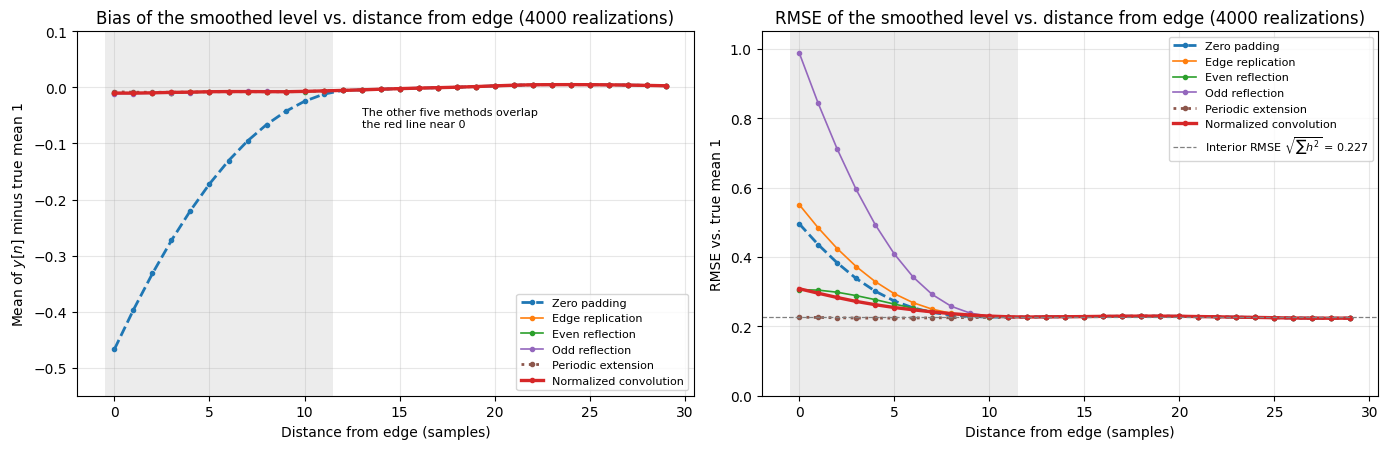

In [25]:
rng_mc = np.random.default_rng(7)
R = 4000
X_mc = 1.0 + rng_mc.standard_normal((R, L_e))          # mean 1, variance 1

mc = {}
for name, fn in edge_methods.items():
    Y = np.array([fn(x, h_e) for x in X_mc])
    mc[name] = dict(bias=Y.mean(axis=0) - 1.0,
                    rmse=np.sqrt(((Y - 1.0) ** 2).mean(axis=0)))

d = np.arange(2 * M_e + 6)          # distance from the left edge (results are symmetric at the right edge)
fig, ax = plt.subplots(1, 2, figsize=(14, 4.6))
for name in edge_methods:
    ax[0].plot(d, mc[name]["bias"][d], marker="o", ms=3, label=name, **edge_styles[name])
    ax[1].plot(d, mc[name]["rmse"][d], marker="o", ms=3, label=name, **edge_styles[name])
rmse_interior = np.sqrt(np.sum(h_e ** 2))
ax[1].axhline(rmse_interior, color="gray", ls="--", lw=0.9,
              label=f"Interior RMSE $\\sqrt{{\\sum h^2}}$ = {rmse_interior:.3f}")
for a, t, yl in zip(ax, ["Bias of the smoothed level", "RMSE of the smoothed level"],
                    ["Mean of $y[n]$ minus true mean 1", "RMSE vs. true mean 1"]):
    a.axvspan(-0.5, M_e - 0.5, color="gray", alpha=0.15, lw=0)
    a.set_title(f"{t} vs. distance from edge ({R} realizations)")
    a.set_xlabel("Distance from edge (samples)")
    a.set_ylabel(yl)
    a.grid(True, alpha=0.3)
ax[0].set_ylim(-0.55, 0.1)
ax[1].set_ylim(0, 1.05)
ax[1].legend(fontsize=8, loc="upper right")
# ---- Theory curves: what the Monte Carlo results should match ----
k = np.arange(-M_e, M_e + 1)
used = [h_e[k <= dd] for dd in d]                       # taps that land on real samples at distance dd
ax[0].text(13, -0.07, "The other five methods overlap\nthe red line near 0", fontsize=8)
ax[0].legend(fontsize=8, loc="lower right")
ax[1].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### Test 3: Noise-free ramp

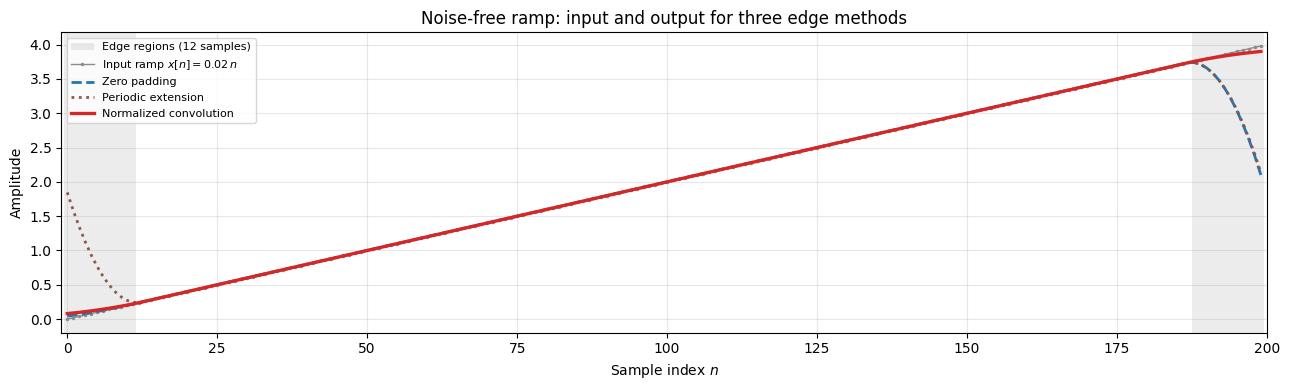

In [26]:
slope = 0.02
x_ramp = slope * np.arange(L_e)

fig, ax = plt.subplots(figsize=(13, 4))
k = np.arange(L_e)
ax.axvspan(-0.5, M_e - 0.5, color="gray", alpha=0.15, lw=0)
ax.axvspan(L_e - M_e - 0.5, L_e - 0.5, color="gray", alpha=0.15, lw=0, label=f"Edge regions ({M_e} samples)")
ax.plot(k, x_ramp, color="0.55", lw=1.0, marker=".", ms=3, label="Input ramp $x[n] = 0.02\\,n$")
for name in ["Zero padding", "Periodic extension", "Normalized convolution"]:
    ax.plot(k, edge_methods[name](x_ramp, h_e), label=name, **edge_styles[name])
ax.set_title("Noise-free ramp: input and output for three edge methods")
ax.set_xlabel("Sample index $n$")
ax.set_ylabel("Amplitude")
ax.set_xlim(-1, L_e)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=8, loc="upper left")
plt.tight_layout()
plt.show()

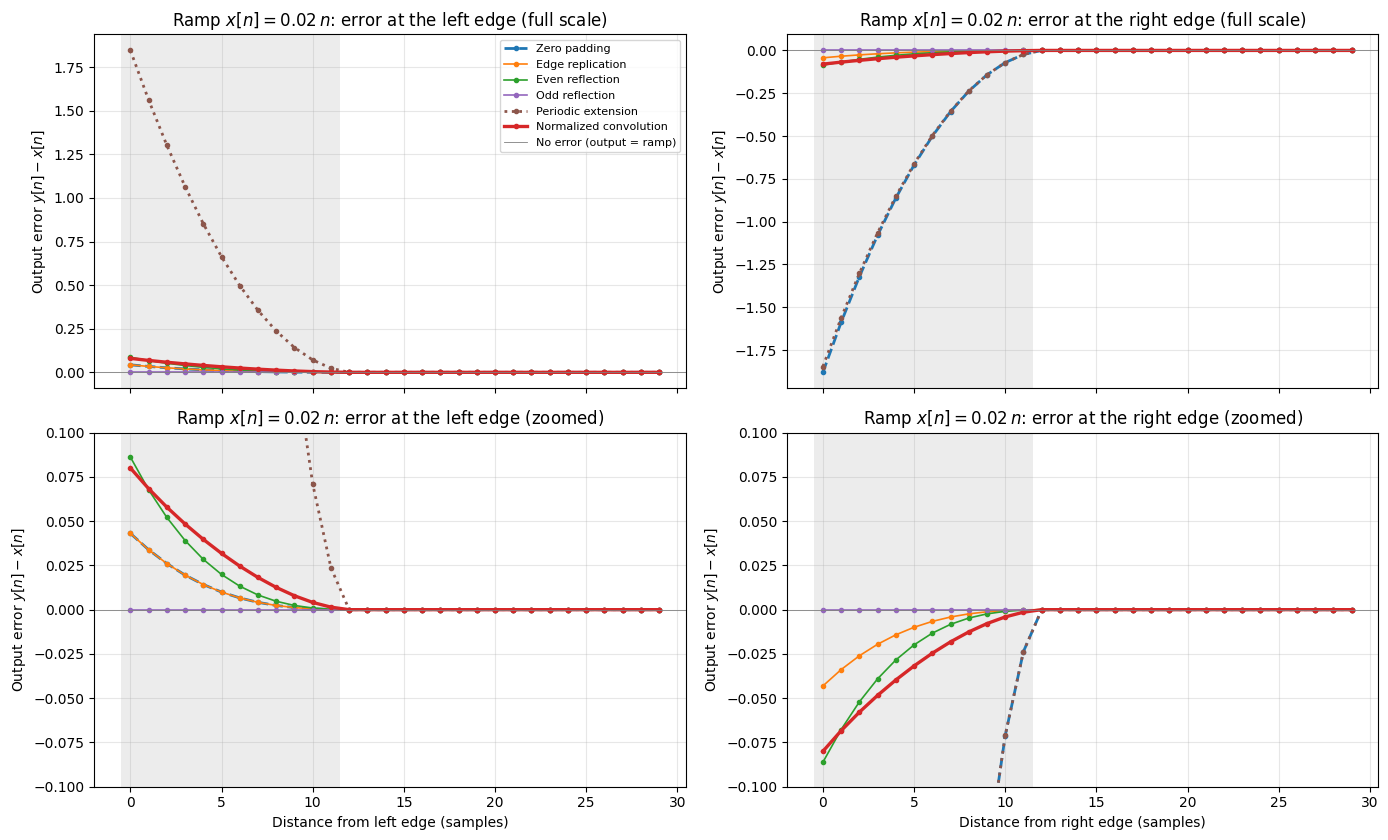

In [27]:
slope = 0.02
x_ramp = slope * np.arange(L_e)
ramp_err = {name: fn(x_ramp, h_e) - x_ramp for name, fn in edge_methods.items()}

fig, ax = plt.subplots(2, 2, figsize=(14, 8.5), sharex=True)
for name in edge_methods:
    left = ramp_err[name][d]                   # distance d from the left edge
    right = ramp_err[name][L_e - 1 - d]        # distance d from the right edge
    for row in range(2):
        ax[row, 0].plot(d, left, marker="o", ms=3, label=name, **edge_styles[name])
        ax[row, 1].plot(d, right, marker="o", ms=3, label=name, **edge_styles[name])
for (r, c), a in np.ndenumerate(ax):
    a.axvspan(-0.5, M_e - 0.5, color="gray", alpha=0.15, lw=0)
    a.axhline(0, color="gray", lw=0.6, label="No error (output = ramp)")
    a.set_ylabel("Output error $y[n] - x[n]$")
    a.grid(True, alpha=0.3)
    side = "left" if c == 0 else "right"
    a.set_title(f"Ramp $x[n] = {slope}\\,n$: error at the {side} edge" + (" (zoomed)" if r == 1 else " (full scale)"))
    if r == 1:
        a.set_ylim(-0.1, 0.1)
        a.set_xlabel(f"Distance from {side} edge (samples)")
ax[0, 0].legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

### Summary table

In [28]:
print(f"{'Method':24s} {'Bias':>8s} {'RMSE':>7s} {'Ramp error':>11s} {'Ramp error':>11s}")
print(f"{'':24s} {'at n=0':>8s} {'at n=0':>7s} {'left end':>11s} {'right end':>11s}")
for name in edge_methods:
    print(f"{name:24s} {mc[name]['bias'][0]:+8.3f} {mc[name]['rmse'][0]:7.3f} "
          f"{ramp_err[name][0]:+11.3f} {ramp_err[name][-1]:+11.3f}")
print(f"\nInterior RMSE for reference: {rmse_interior:.3f}")

Method                       Bias    RMSE  Ramp error  Ramp error
                           at n=0  at n=0    left end   right end
Zero padding               -0.467   0.496      +0.043      -1.880
Edge replication           -0.011   0.551      +0.043      -0.043
Even reflection            -0.010   0.306      +0.086      -0.086
Odd reflection             -0.011   0.989      -0.000      +0.000
Periodic extension         -0.008   0.226      +1.846      -1.846
Normalized convolution     -0.010   0.308      +0.080      -0.080

Interior RMSE for reference: 0.227


### My recommendation: normalized convolution, with the edge samples flagged

**What the tests show** (values at the edge sample, $n = 0$ or $n = L-1$)

| Method | Bias on mean-1 noise | RMSE on noise (interior: 0.23) | Ramp error | Verdict |
|---|:---:|:---:|:---:|---|
| Zero padding | −0.47 | 0.50 | −1.88 (right end) | Worst: pulls the output toward 0 |
| Edge replication | ≈ 0 | 0.55 | ±0.04 | Noisy: leans on one sample, $x[0]$ |
| Odd reflection | ≈ 0 | 0.99 | 0 | No smoothing at the endpoint: $y[0] = x[0]$ |
| Periodic extension | ≈ 0 | 0.23 | ±1.85 | Fails whenever the two ends differ |
| Even reflection | ≈ 0 | 0.31 | ±0.09 | Good |
| **Normalized convolution** | ≈ 0 | 0.31 | ±0.08 | **Good (my choice)** |

No method wins every test. Even reflection and normalized convolution tie for the best overall balance.

**Why normalized convolution over even reflection**

1. **It uses only real data.** Every output is a weighted average of samples that actually exist. Even reflection quietly reuses samples.
2. **The DC gain is exactly 1 everywhere, and the output stays within the range of the input.** Non-negative data can never produce a negative smoothed value.
3. **It still works when the filter is longer than the signal** (the 113-tap binomial filter on the 100-sample sinusoid) **or when the data has gaps.**
4. **The highpass filter inherits it.** In Problem 3, $x - (\text{smoothed } x)$ keeps zero DC gain right up to the edges.

**This only works because $h[n] \ge 0$.** The denominator $\sum h[k]$ is then always positive. For a filter with negative taps, the sum of the remaining taps can approach zero or change sign, and the method breaks down.

## Problem 5: What type of circumstances would you want to apply this type of filter, rather than a well-designed frequency selective filter? What are the design tradeoffs?

To make the tradeoffs concrete, I compare the Problem 2 smoothers designed for $\omega_c = 0.1\pi$ with an **equiripple (Parks-McClellan) lowpass filter** designed for the same $-3$ dB cutoff: passband edge $0.07\pi$, stopband edge $0.15\pi$, $N = 61$ taps. The equiripple design is optimal in the minimax sense, so it represents the best a frequency-selective FIR design can do at that length.

The time-domain tests use zero-phase (centered) filtering with edge replication for **every** filter, so the comparison is fair. (Normalized convolution can't be used for the equiripple filter because its taps go negative; see Problem 4.)

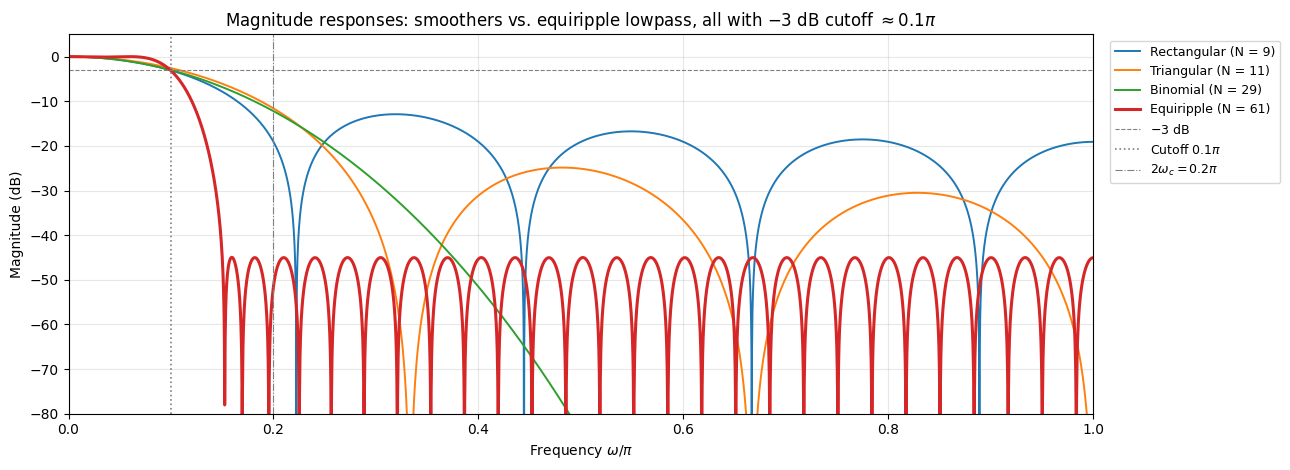

In [29]:
from scipy.signal import remez

# ---- Equiripple lowpass, centered at n = 0 like the other filters ----
N_eq = 61
h_eq = remez(N_eq, [0, 0.07, 0.15, 1.0], [1, 0], fs=2.0)   # band edges in units of pi
h_eq = h_eq / h_eq.sum()                                   # exact unit DC gain
M_eq = (N_eq - 1) // 2


def cutoff_from_taps(h):
    M = (len(h) - 1) // 2
    A = np.abs(amplitude_response(h, M, w_grid))
    return w_grid[np.argmax(A < 1 / np.sqrt(2))]


compare = {}
for name in filters:
    key = min(design[name], key=lambda t: abs(t - 0.1))
    compare[f"{name} (N = {2*design[name][key]+1})"] = filters[name](design[name][key])[1]
compare[f"Equiripple (N = {N_eq})"] = h_eq
cmp_colors = dict(zip(compare, ["C0", "C1", "C2", "C3"]))


def zero_phase_filter(x, h):
    return filter_padded(x, h, "edge")


# Non-negative test signal: pulses of different widths (e.g., event counts or intensities)
x_pulse = np.zeros(200)
x_pulse[40:43] = 1.0          # narrow pulse
x_pulse[90:110] = 1.0         # wide pulse
x_pulse[160] = 1.0            # single-sample impulse

fig, ax = plt.subplots(figsize=(13, 4.8))
for name, h in compare.items():
    M = (len(h) - 1) // 2
    A = amplitude_response(h, M, w_grid)
    ax.plot(w_grid / np.pi, 20 * np.log10(np.maximum(np.abs(A), 1e-6)), color=cmp_colors[name],
            lw=2.2 if "Equiripple" in name else 1.4, label=name)
ax.axhline(-3, color="gray", ls="--", lw=0.8, label="$-3$ dB")
ax.axvline(0.1, color="gray", ls=":", lw=1.2, label="Cutoff $0.1\\pi$")
ax.axvline(0.2, color="gray", ls="-.", lw=0.8, label="$2\\omega_c = 0.2\\pi$")
ax.set_title("Magnitude responses: smoothers vs. equiripple lowpass, all with $-3$ dB cutoff $\\approx 0.1\\pi$")
ax.set_xlabel("Frequency $\\omega/\\pi$")
ax.set_ylabel("Magnitude (dB)")
ax.set_xlim(0, 1)
ax.set_ylim(-80, 5)
ax.grid(True, alpha=0.3)
ax.legend(fontsize=9, loc="upper left", bbox_to_anchor=(1.01, 1.0))
plt.tight_layout()
plt.show()

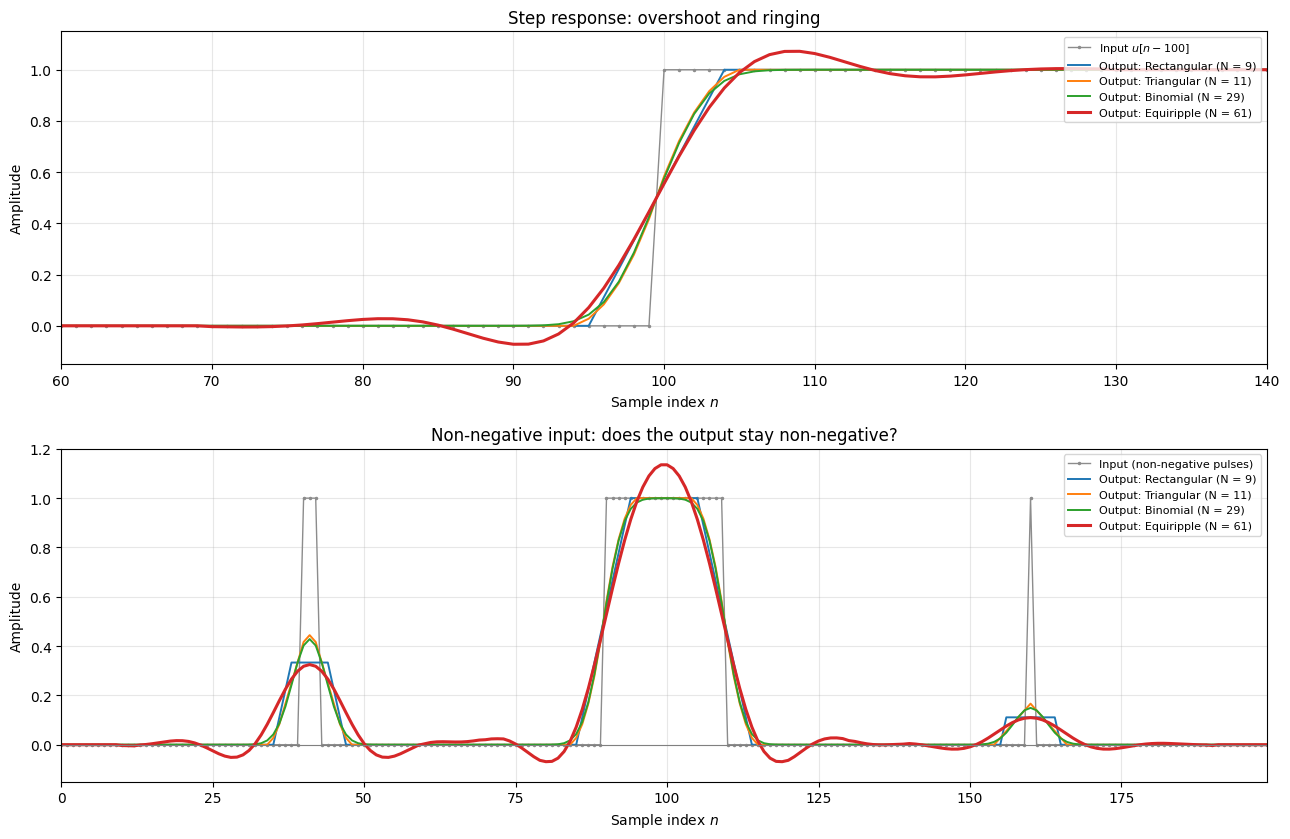

In [30]:
fig, ax = plt.subplots(2, 1, figsize=(13, 8.5))
k = np.arange(200)

a = ax[0]
a.plot(k, x_step, color="0.55", lw=1.0, marker=".", ms=3, label="Input $u[n-100]$")
for name, h in compare.items():
    a.plot(k, zero_phase_filter(x_step, h), color=cmp_colors[name],
           lw=2.2 if "Equiripple" in name else 1.4, label=f"Output: {name}")
a.set_title("Step response: overshoot and ringing")
a.set_xlim(60, 140)
a.set_ylim(-0.15, 1.15)

a = ax[1]
a.plot(k, x_pulse, color="0.55", lw=1.0, marker=".", ms=3, label="Input (non-negative pulses)")
for name, h in compare.items():
    a.plot(k, zero_phase_filter(x_pulse, h), color=cmp_colors[name],
           lw=2.2 if "Equiripple" in name else 1.4, label=f"Output: {name}")
a.axhline(0, color="gray", lw=0.8)
a.set_title("Non-negative input: does the output stay non-negative?")
a.set_xlim(0, 199)
a.set_ylim(-0.15, 1.2)

for a in ax:
    a.set_xlabel("Sample index $n$")
    a.set_ylabel("Amplitude")
    a.grid(True, alpha=0.3)
    a.legend(fontsize=8, loc="upper right")
plt.tight_layout()
plt.show()

In [31]:
def ops_per_output(name, N):
    # Arithmetic per output sample for an efficient implementation
    M = (N - 1) // 2
    if name.startswith("Rectangular"):
        return "2 adds, 1 scale (running sum)"
    if name.startswith("Triangular"):
        return "4 adds, 1 scale (two running sums)"
    if name.startswith("Binomial"):
        return f"{2*M} adds, 1 shift ([1,1] cascade)"
    return f"{M+1} mults, {N-1} adds (symmetric FIR)"


print(f"{'Filter':22s} {'-3 dB':>7s} {'Gain at':>8s} {'Atten. at':>10s} {'Step':>10s} {'Min output,':>12s}  Arithmetic per output")
print(f"{'':22s} {'cutoff':>7s} {'0.05π':>8s} {'0.2π (dB)':>10s} {'overshoot':>10s} {'pulse input':>12s}")
for name, h in compare.items():
    M = (len(h) - 1) // 2
    A = amplitude_response(h, M, w_grid)
    g05 = np.abs(amplitude_response(h, M, np.array([0.05 * np.pi])))[0]
    stop = 20 * np.log10(np.abs(A[w_grid >= 0.2 * np.pi]).max())
    ys = zero_phase_filter(x_step, h)
    yp = zero_phase_filter(x_pulse, h)
    print(f"{name:22s} {cutoff_from_taps(h)/np.pi:6.3f}π {g05:8.3f} {stop:10.1f} "
          f"{100*(ys.max()-1):9.1f}% {yp.min():+12.3f}  {ops_per_output(name, len(h))}")

Filter                   -3 dB  Gain at  Atten. at       Step  Min output,  Arithmetic per output
                        cutoff    0.05π  0.2π (dB)  overshoot  pulse input
Rectangular (N = 9)     0.099π    0.920      -12.9       0.0%       +0.000  2 adds, 1 scale (running sum)
Triangular (N = 11)     0.108π    0.930      -11.6       0.0%       +0.000  4 adds, 1 scale (two running sums)
Binomial (N = 29)       0.100π    0.917      -12.2       0.0%       +0.000  28 adds, 1 shift ([1,1] cascade)
Equiripple (N = 61)     0.099π    0.996      -45.0       7.2%       -0.069  31 mults, 60 adds (symmetric FIR)


### When to use a non-negative smoother instead of a frequency-selective filter

**What the comparison shows**

- **Frequency selectivity: the equiripple filter wins.** At $0.2\pi$ it attenuates by about 45 dB, while the smoothers manage only about 12 dB. The smoothers also droop inside the passband (gain of about 0.92 at $0.05\pi$, versus 1.0 for equiripple).
- **Time-domain behavior: the smoothers win.** Their step response has **no overshoot**, and a non-negative input never produces a negative output. The equiripple filter overshoots by about 7% and rings at every edge.
- **Cost: the smoothers win.** A moving average is a running sum and needs essentially no multiplies. The equiripple filter needs 31 multiplies per output.

**Use a non-negative smoother when:**

1. **The time-domain shape matters:** edges, peaks, thresholds, trends. Ringing would create false peaks or false threshold crossings.
2. **The signal is physically non-negative:** counts, intensities, pixel values, power.
3. **Computation is limited:** embedded systems or FPGAs. CIC decimators are cascaded moving averages for this reason.

**Use a frequency-selective filter when:**

1. **Two components are close in frequency** and must be separated (for example, removing a 60 Hz line).
2. **There is a stopband specification** (for example, $-60$ dB anti-aliasing before decimation).
3. **The passband must be flat** for amplitude accuracy.

**Summary**

| | Non-negative smoother | Frequency-selective (equiripple) |
|---|---|---|
| Transition band | Wide | Narrow |
| Stopband attenuation | Poor (−13 to −26 dB sidelobes) | High, set by the design spec |
| Step response | No overshoot | Overshoot and ringing (≈ 7%) |
| Output range | Always within the input range | Can exceed it or go negative |
| Design effort | One parameter (length) | Band edges, ripple, weights |
| Cost | Nearly multiplier-free | One multiply per pair of taps |

# Project

<div style="background-color:#ffe6e6; border:3px solid #cc0000; border-radius:6px; padding:14px; text-align:center;">
  <span style="color:#cc0000; font-size:1.5em; font-weight:bold;">
    ⚠️ THE FOLLOWING APPLICAITON OF A NON-NEGATIVE FIR FILTER WAS DONE WITH AI ⚠️
  </span>
</div>

## Problem 7: What is the problem?

### The problem

From video of a transmission span, estimate each conductor's galloping mode, frequency, and peak-to-peak amplitude, and raise an alert **quickly and without false alarms**. Each span station gives a vertical-displacement signal sampled at 30 fps:
$$
x[n] = \underbrace{\text{gallop}}_{\text{signal}} + \underbrace{b[n]}_{\text{blowout}} + \underbrace{s[n]}_{\text{camera shake}} + \underbrace{v[n]}_{\text{noise}}
$$

What makes this hard:

- **Gallop and blowout are close in frequency.** The gallop modes sit at about 0.25, 0.50, and 0.76 Hz, and blowout sits just below 0.25 Hz.
- **The measurement is coarse:** about 0.21 m per pixel at default.
- **The alert must be fast** (≤ 30 s), yet never trigger on blowout or ice shedding.

### Where non-negative FIR filters fit

Following Problem 5, the project question becomes: **where is a simple smoother good enough, and what do I give up?**

**1. Blowout rejection: subtract the smoothed signal (the Problem 3 highpass).**
The gallop modes are harmonics: $f_n = n f_1$. A moving average exactly one gallop period long ($\approx 3.9$ s) has zeros at $f_1, 2f_1, 3f_1, \dots$. It therefore captures the blowout but none of the gallop, and subtracting it removes the blowout while leaving every gallop mode untouched. Applying the subtraction twice, $(1 - H)^2$, makes the blowout rejection stronger.

| | Kaiser FIR (proposal) | Moving-average complement |
|---|---|---|
| Blowout attenuation at 0.05 Hz | ≥ 40 dB | 48.8 dB |
| Gain at the gallop modes | ±0.5 dB | ±0.5 dB |
| Gain between modes | flat | up to +3.4 dB |
| Delay | ≈ 11 s | ≈ 3.7 s |
| Arithmetic | 167-tap convolution | two running sums |

**Trade-off:** the passband is not flat, but that's acceptable because gallop energy only sits at the harmonics. In exchange, the delay drops by about 3×, which directly helps alert speed. The catch is that the moving-average length depends on knowing $f_1$; a 5% error in $f_1$ costs about 1.4 dB.

**2. Smoothing the amplitude for the alert.** Square the high-pass output and average it over one gallop period with the same moving average. This gives a ripple-free power estimate, and the amplitude follows from it ($\sqrt{2}\times$ RMS for one mode). Because the taps are non-negative:
- the estimate never overshoots, so a sudden transient such as ice shedding can't briefly spike past the alert threshold;
- the delay is about 4 s, versus 16 s for the STFT.

**3. Smoothing the PSD without segmenting.** Instead of Welch's method, smooth one long periodogram **across frequency** with a non-negative kernel. The PSD stays non-negative, and the total power is preserved.

## Problem 6: Who is the problem important to and why? What would the impact be if you were successful in developing an accurate algorithm?

### Who the problem matters to

- **Transmission utilities and system operators.** Galloping can cause phase-to-phase flashovers, damaged hardware, and, in severe cases, structural failure. Today a utility usually learns of an event only after the damage is done. A live alert would tell operators which span is galloping while it is happening, so they can act on it (send crews, plan around repeated faults on that line) instead of reconstructing the event afterward.
- **Line designers and maintenance engineers.** Galloping is rare and hard to observe, so there is little measured data on real events: which mode, how large, and at what wind speed. Measured mode and amplitude records from real spans would let engineers check clearance designs against actual motion and judge whether anti-galloping countermeasures are working.
- **Researchers and standards groups.** Camera-based gallop measurement has been shown to work (Yang et al.; CIGRE ISH 2015), and the IEEE P2828 working group is writing a guide for it. The published work, however, says little about the discrete-time design decisions (decimation, filter type, window length, smoothing, alert logic) or how they trade accuracy against latency.

### Impact of an accurate algorithm

- **Inexpensive, non-contact monitoring.** A fixed camera becomes a gallop sensor, with no hardware installed on energized conductors.
- **Trustworthy alerts.** An alert that fires within a known latency and does **not** fire on blowout or ice shedding is one an operator can act on. False alarms matter as much as accuracy: an alert that cries wolf gets ignored.
- **Calibrated event records.** Mode number, frequency, and peak-to-peak amplitude in metres for every event, which is exactly the field data designers lack.
- **Design guidance.** Because every design choice is scored against simulator ground truth, the project shows which choices actually matter. That is useful to anyone building a similar monitor, including groups working on the P2828 guide.

## Problem 8: What instrumentation or data do you have available to support this project?

### Data

- **Physics-based synthetic video generator.** I built this before the proposal as Step 1 of the gallop-monitoring effort. It renders a 250 m span of Drake ACSR with 6 mm of glaze ice, plus a steel shield wire. A calibrated pinhole camera views the span broadside at 1280 × 720 and 30 fps. Gallop follows coupled Den Hartog dynamics under a scripted wind schedule (4 → 16 m/s and back). Blowout, turbulent gusts, ice shedding, weather, camera shake, and sensor noise can each be switched on or off.
- **Exact per-frame ground truth.** Each run writes a CSV of modal coordinates, displacements, pixel positions at 25, 50, and 75 % of the span, amplitude envelopes, and alert labels. It also writes `metadata.json` with the camera matrices (K, R, t), conductor properties, sag, and modal frequencies. Because the modal coordinates are logged, I can compare the high-pass output with the true gallop component sample by sample. I can also check the period-matched smoother against the true $f_1$.
- **Scenario matrix S1–S8.** These isolate each confounder:
  - S5 (blowout only) tests the blowout residual of the high-pass designs.
  - S6 (ice shedding) tests whether a transient can cause a false alert.
  - S3 (stepped amplitude) is a direct test of the envelope smoother's step response and overshoot.
  - S8 repeats the nominal case over 10 random seeds, giving the variance of every metric.
- **Test signals.** I can inject sinusoids of known frequency and amplitude, plus steps, to verify filter responses and spectral scaling, the same way I checked the periodogram scaling in this homework.
- **Reference data.** The EPRI Orange Book provides field statistics (mode counts, orbit shape) and empirical amplitude relations (Hunt–Richards, Lilien–Havard) as sanity checks on simulated amplitudes.

### Instrumentation and tools

- Python 3.10+ with NumPy, SciPy, and OpenCV on a laptop or desktop. Each filter and spectral step is written out directly and checked against `scipy.signal`.
- A function generator and oscilloscope on my home bench. These could drive and verify a small vibrating-wire rig if I pursue the bench-rig stretch goal.

### What is not available

No real gallop footage with ground truth exists to my knowledge, so the quantitative evaluation relies on the simulator. I will frame results as relative comparisons between designs rather than absolute field performance.

## Problem 9: How do you plan to display your results. What tables or figures will you include?

All results will be in physical units (metres, hertz, seconds) and scored against the simulator ground truth.

### Figures

1. **Blowout-filter comparison:**
   - magnitude response (dB) of the Kaiser FIR, the Butterworth IIR, and the period-matched $(1-H)^2$ filter, overlaid on the specification mask, with $f_1$, $f_2$, and $f_3$ marked;
   - group delay of each design;
   - impulse responses;
   - a pole–zero plot for the IIR design.
2. **Time-domain example at one span station:**
   - raw displacement and the smoothed blowout estimate;
   - high-pass output overlaid on the true gallop component;
   - edge regions shaded, as in this homework.
3. **Spectrogram:** the STFT with the true modal frequencies overlaid, showing gallop growing and dying away with the wind schedule.
4. **PSD comparison over a steady-gallop interval:** raw periodogram, frequency-smoothed (Daniell) periodogram, and Welch estimate on the same axes.
5. **Envelope and alerts:**
   - estimated semi-amplitude from the boxcar-smoothed power, the Hilbert envelope, and the STFT, against the ground-truth envelope;
   - the 0.75 m and 0.50 m thresholds;
   - estimated and true alert raise/clear times.

   I will show this for the stepped-amplitude scenario (S3) and the ice-shedding scenario (S6).
6. **Latency–accuracy trade-off:** median alert latency against RMS amplitude error for each filter and smoother design and each window length.
7. **Sensitivity of the period-matched filter:** gain at $f_1$ against the error in the predicted $f_1$.

### Tables

1. **Filter-specification compliance** for each design:
   - attenuation at 0.05 Hz;
   - passband ripple;
   - gain at $f_1$–$f_3$;
   - delay;
   - arithmetic per sample.
2. **Performance metrics** P1–P7 for each scenario (S1–S7) and each blowout filter, with pass/fail against the targets.
3. **Monte Carlo results (S8):** mean ± standard deviation of every metric over 10 seeds.

## Problem 10: What, if anything, did you learn from this homework?

* **Normalized convolution for edge handling**
  At the ends of a signal, the filter is applied only to the samples that exist, and the result is divided by the sum of the taps that were used. Unlike zero padding, this keeps the DC gain at exactly 1 at the edges. I used it for every filtered output in Problems 2 and 3, and recommended it in Problem 4. It only works because $h[n] \ge 0$.

* **Periodograms**
  A PSD estimate made from a single FFT of the entire record, scaled by $1/(2\pi L)$ so that the area under the PSD equals the signal's average power. I used it for all the input and output PSDs in Problems 2 and 3, in place of Welch's method, which fails on the step because its short segments are mostly all 0s or all 1s.

* **Spectral inversion**
  Turning a lowpass filter into a highpass filter by subtracting its output from the original signal: $h_{\text{hp}}[n] = \delta[n] - h_{\text{lp}}[n]$, so $H_{\text{hp}} = 1 - H_{\text{lp}}$. This is how I built the highpass filter in Problem 3. The triangular prototype worked best because its response never goes negative, so the highpass never overshoots unity gain.

* **Monte Carlo testing**
  Repeating a random experiment many times and averaging, so that a systematic error (bias) can be separated from random noise. In Problem 4, I filtered 4000 independent noise records to measure each edge method's bias and RMSE at each distance from the edge, and the results matched the theoretical predictions.

* **Noise-free ramp testing for method handling of trends at a boundary**
  A symmetric filter with unit DC gain passes a straight line through unchanged in the interior, so any output error on a clean ramp comes from the edge method alone. In Problem 4, this test isolated how each method handles a trend: odd reflection was exact, and periodic extension and zero padding failed badly.

* **Spectrograms of the STFT**
  A plot of how a signal's frequency content changes over time, made from FFTs of short, overlapping windows. It isn't used in the homework itself. I plan to use it in my gallop project (Problems 7 and 9) to track the gallop mode frequencies as they grow and die away.

## Problem 11: What new questions, if any, do you have?

I have no questions at this time.